<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/Usando_Sweetviz_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Fast & powerful EDA in notebooks using Sweetviz 2.0

In [1]:
!pip install sweetviz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.1/15.1 MB 71.6 MB/s eta 0:00:00


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("himanshunakrani/\
        naive-bayes-classification-data")

print("Path to dataset files:", path)

100%|██████████| 2.02k/2.02k [00:00<00:00, 2.63MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/himanshunakrani/naive-bayes-classification-data/versions/1


In [5]:
import pandas as pd
import os

file_path = os.path.join(path, 'Naive-Bayes-Classification-Data.csv')

# Usamos pd.read_csv para cargar el archivo
df = pd.read_csv(file_path)
df.head()

,glucose,bloodpressure,diabetes
0,40,85,0
1,40,92,0
2,45,63,1
3,45,80,0
4,40,73,1


In [6]:
from sklearn.model_selection import train_test_split

# Definimos las características (X) y la variable objetivo (y)
X = df[['glucose', 'bloodpressure']]
y = df['diabetes']

# Dividimos en 80% train y 20% test
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.2,
                                                    random_state=42)

print(f"Dimensiones de X_train: {X_train.shape}")
print(f"Dimensiones de X_test: {X_test.shape}")

Dimensiones de X_train: (796, 2)
Dimensiones de X_test: (199, 2)


In [7]:
import sweetviz as sv
import pandas as pd
train_df = X_train
test_df = X_test

In [9]:
from sklearn.model_selection import train_test_split

# Dividimos el DataFrame completo para que contenga también la columna 'diabetes'
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# Generamos el reporte usando la columna en minúscula 'diabetes'
comparison_report = sv.compare([train_df,
                                'Train'], [test_df,
                                           'Test'], target_feat='diabetes')

                                             |          | [  0%]   00:00 -> (? left)


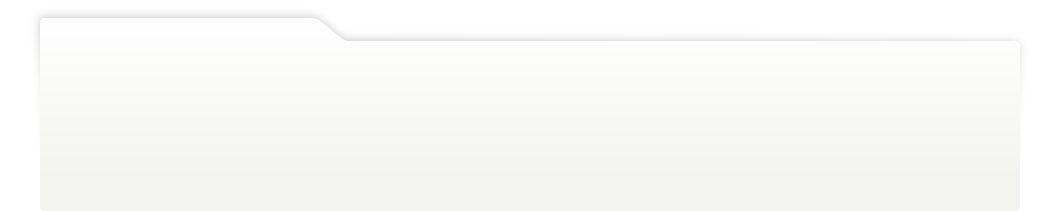
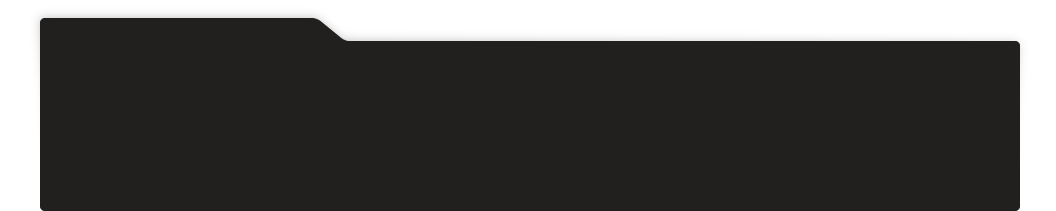
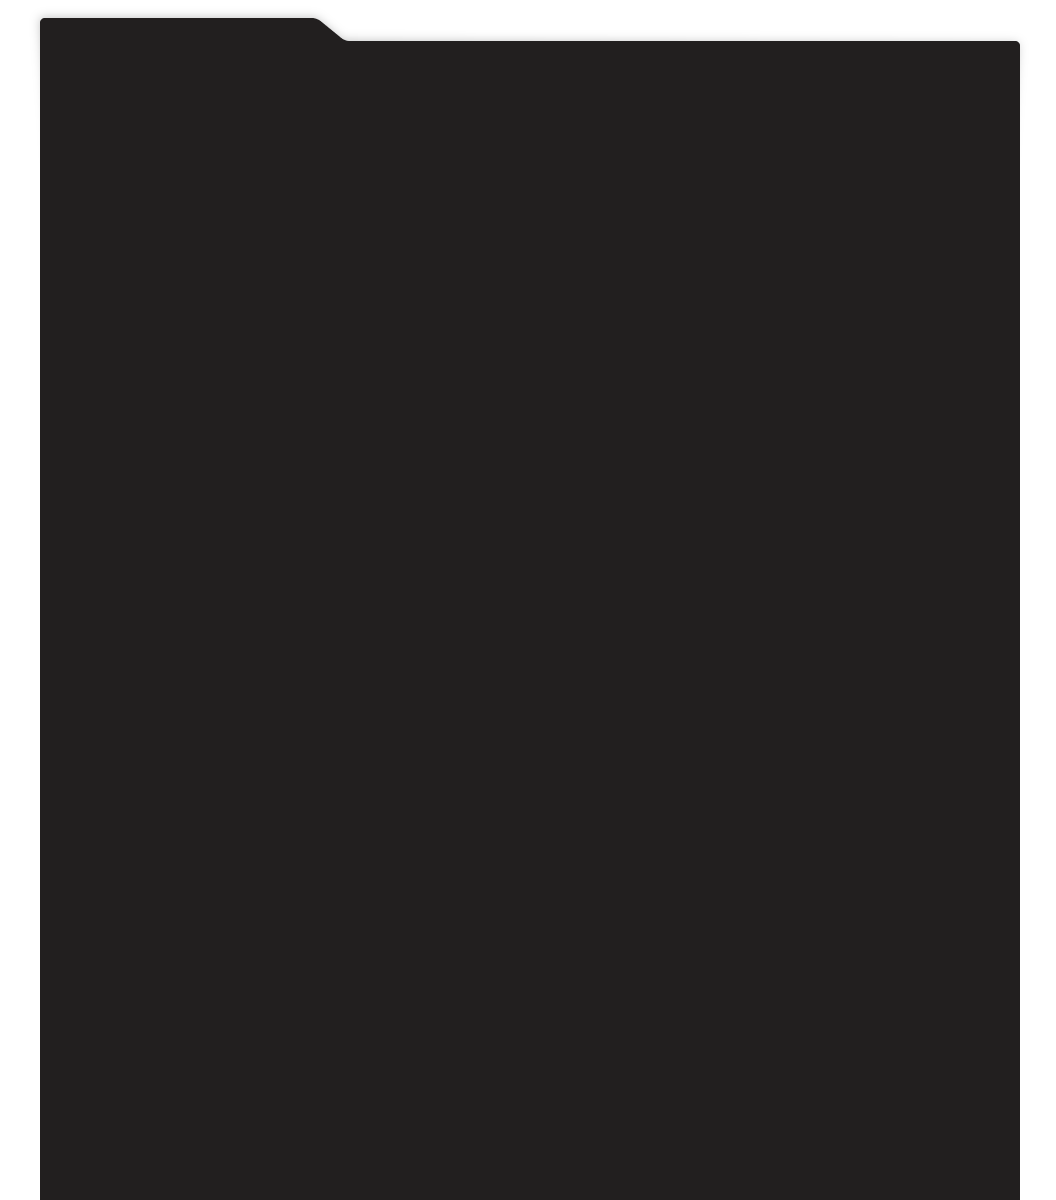
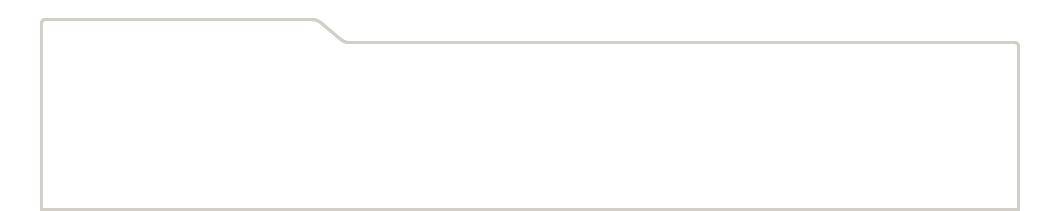
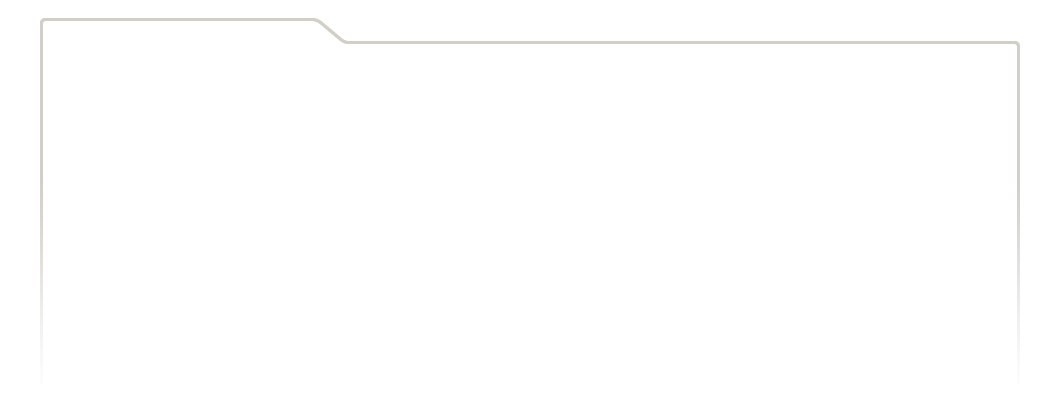
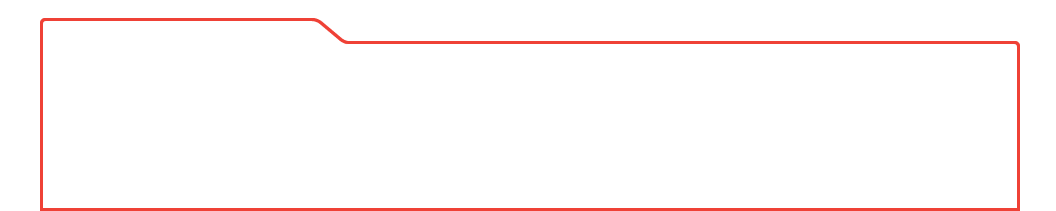
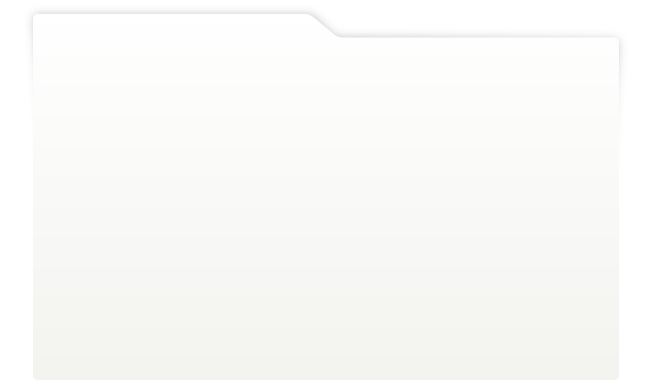
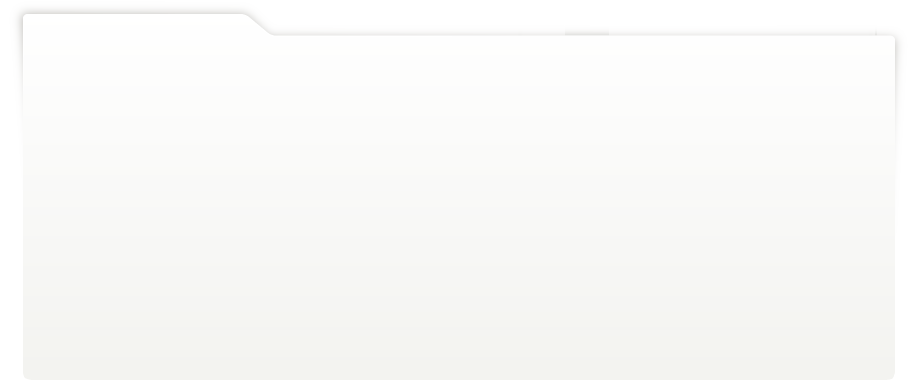
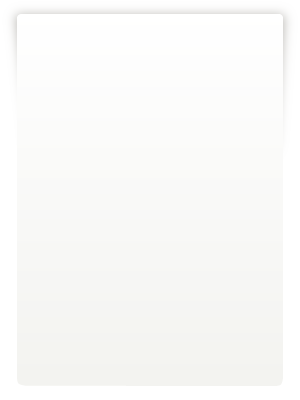
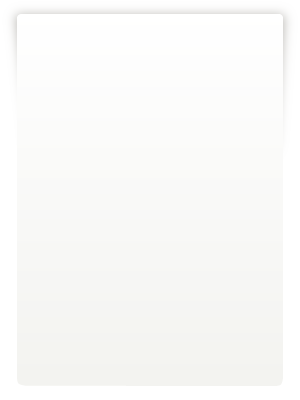
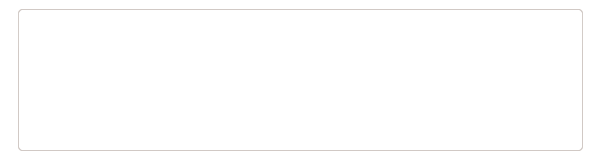
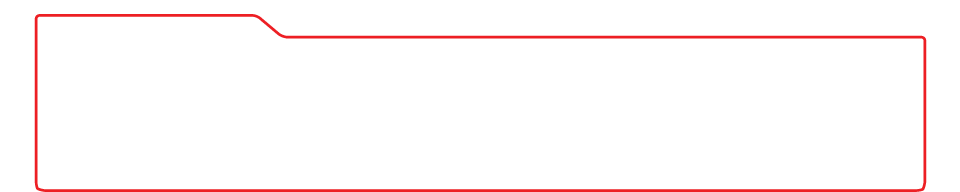
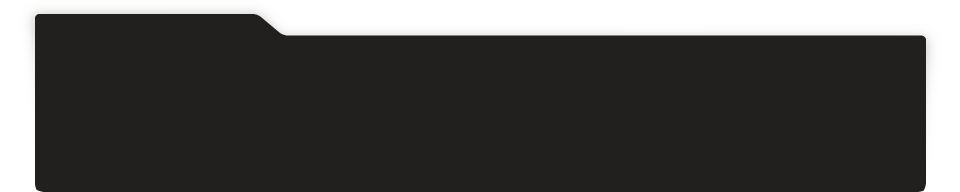
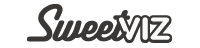
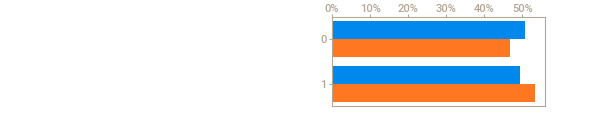
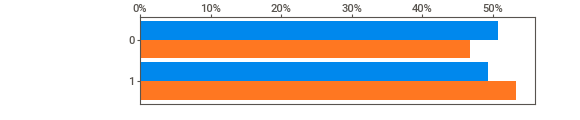
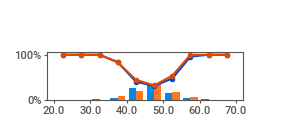
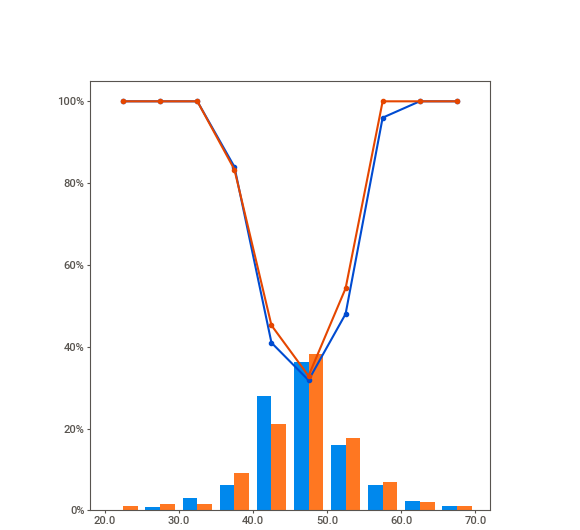
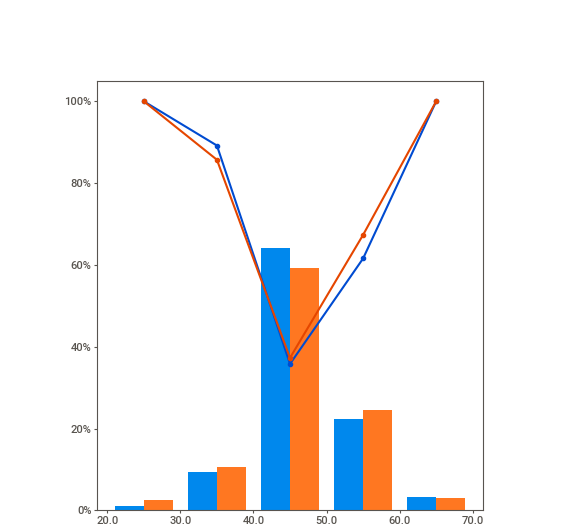
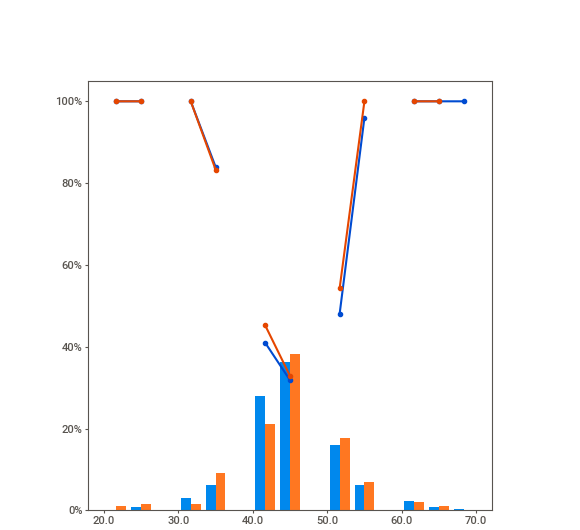
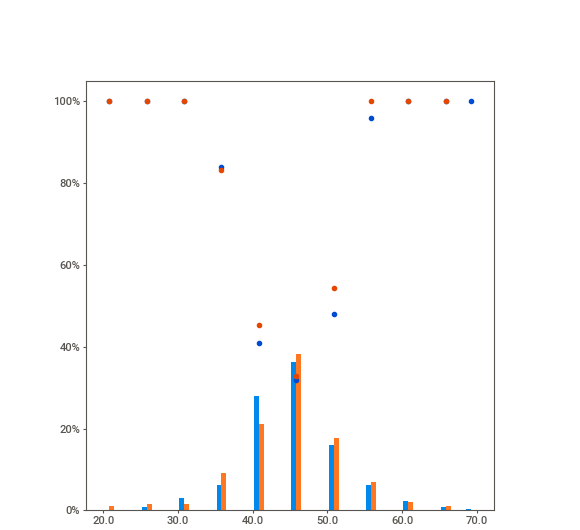
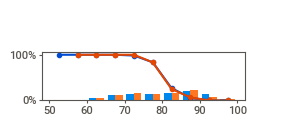
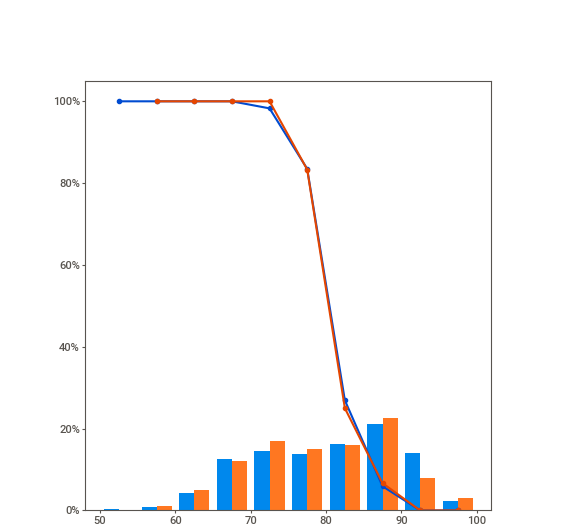
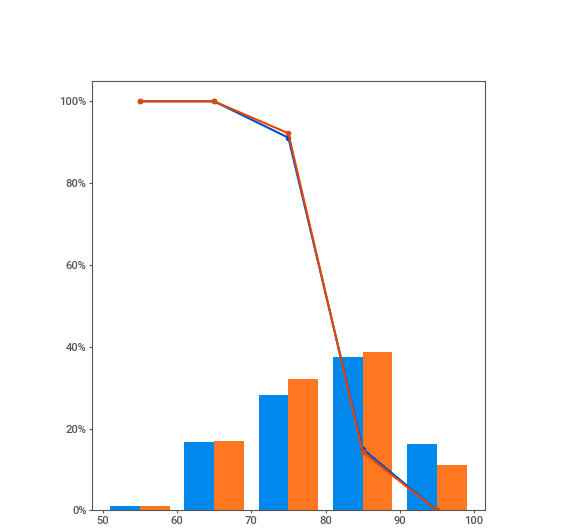
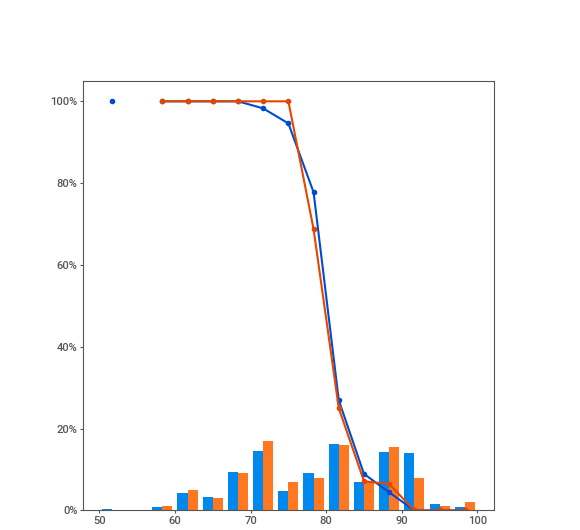
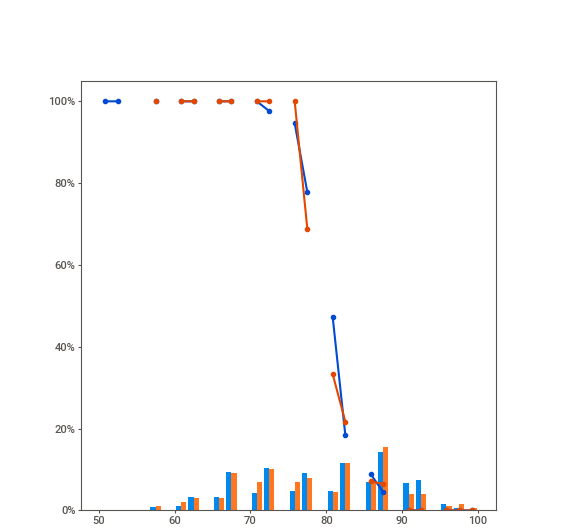
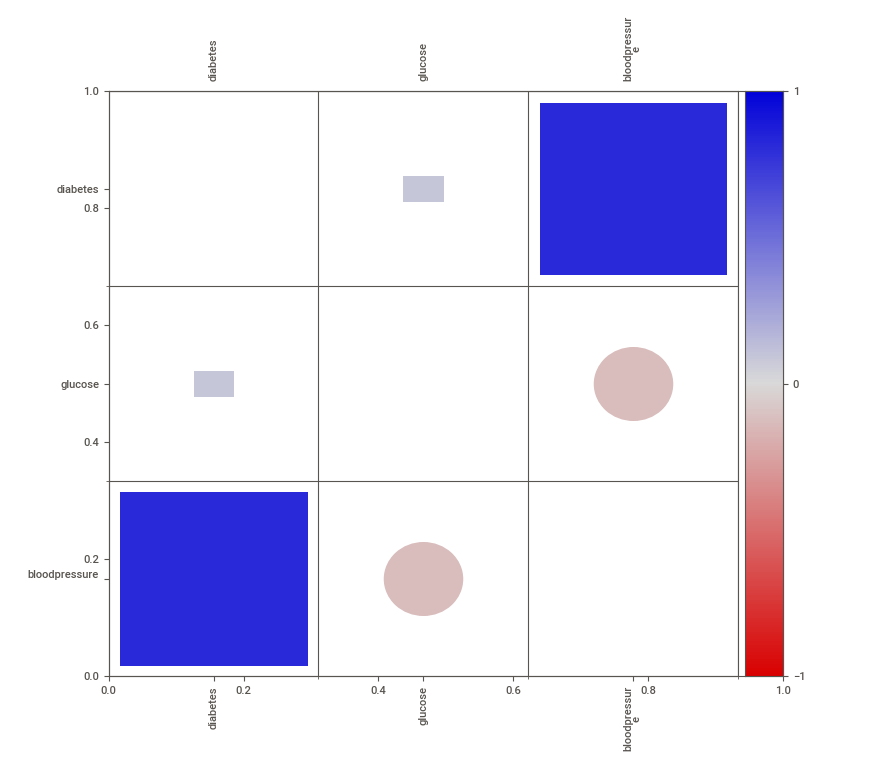
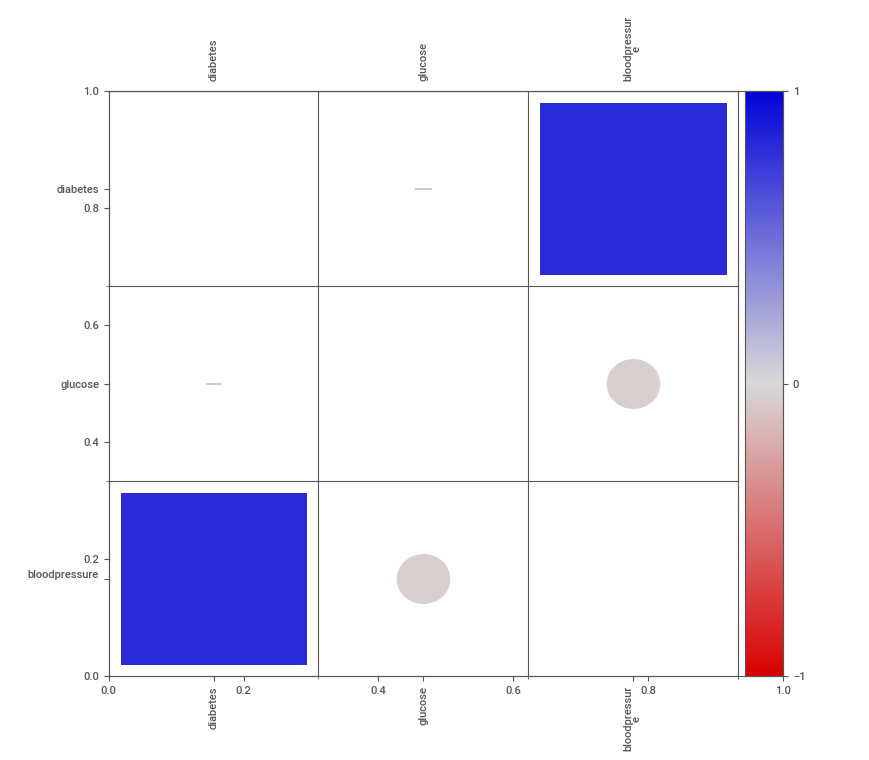

In [10]:
# Visualizar el reporte directamente en el cuaderno
comparison_report.show_notebook()


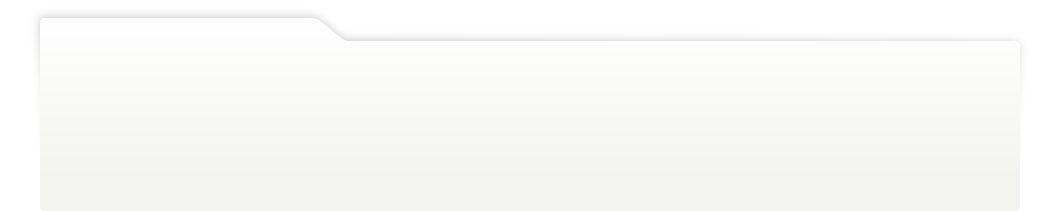
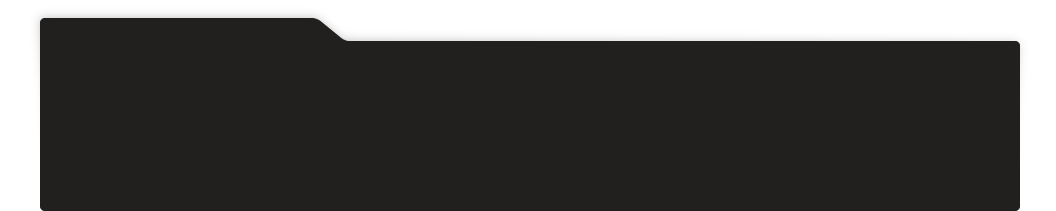
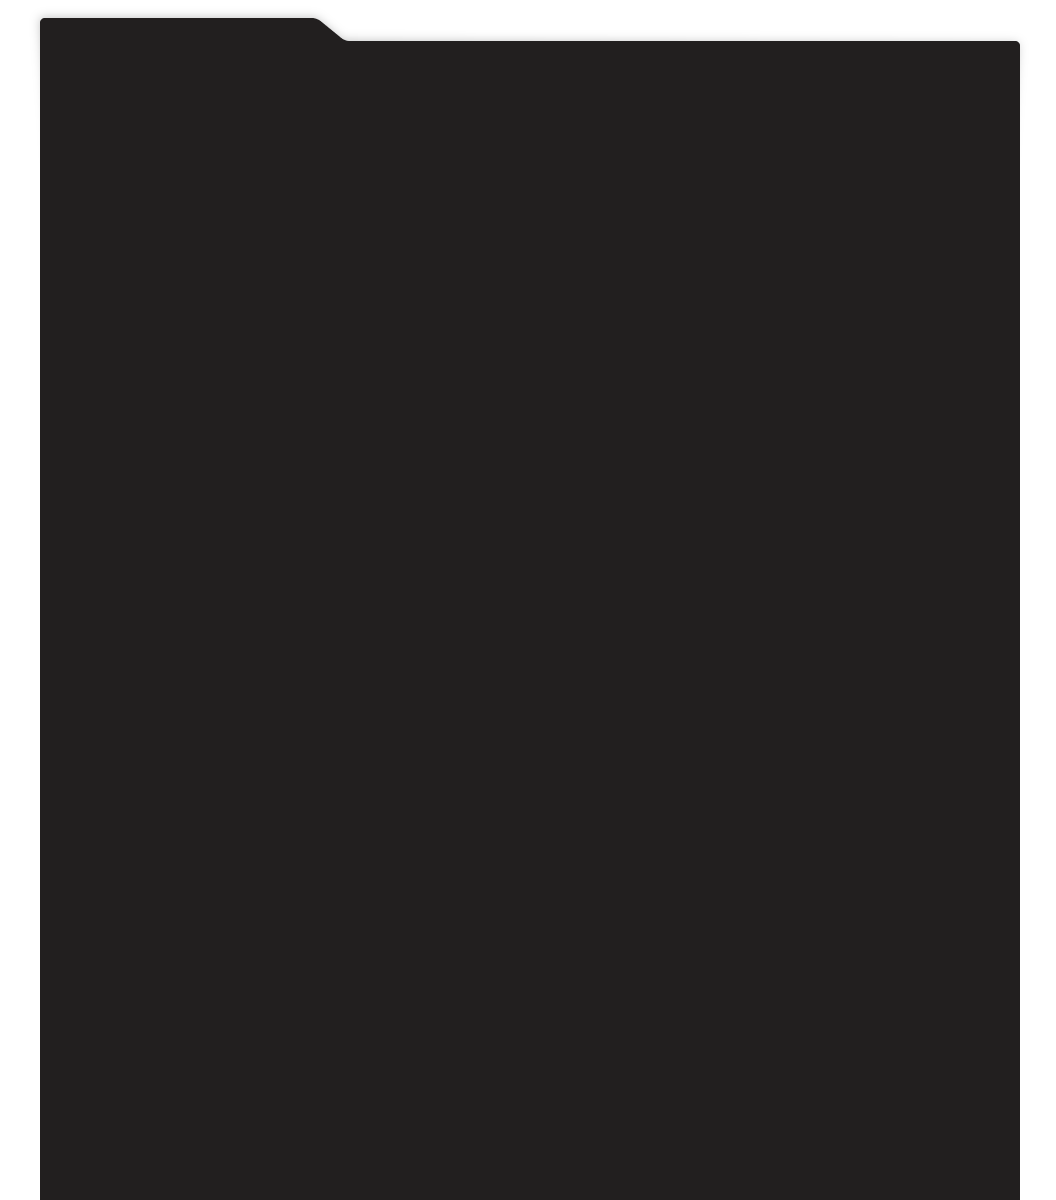
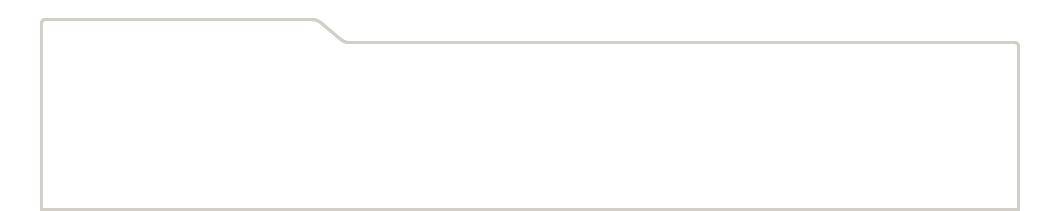
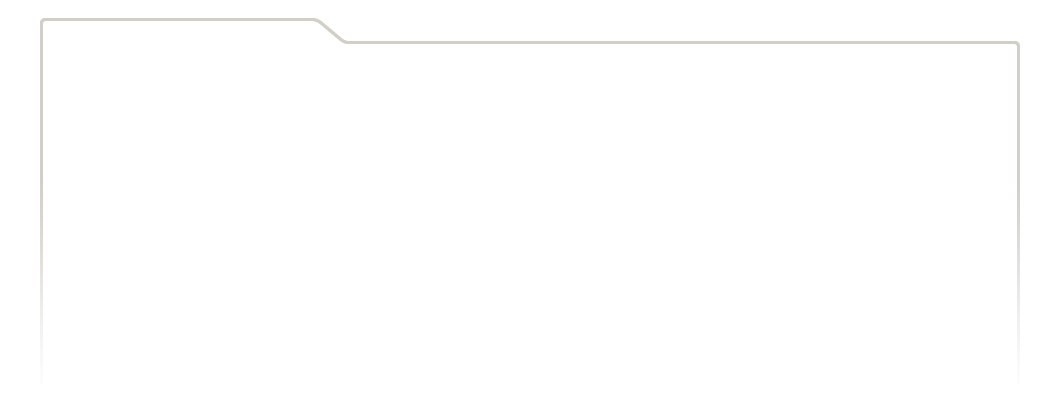
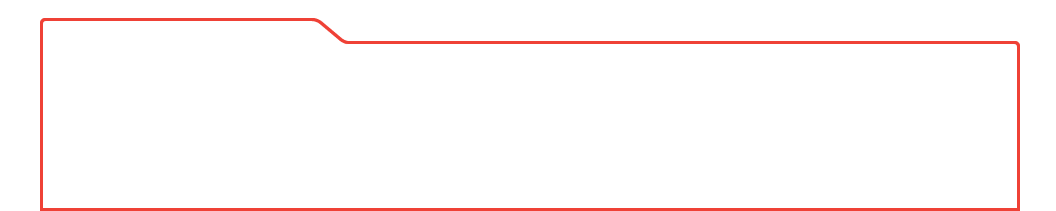
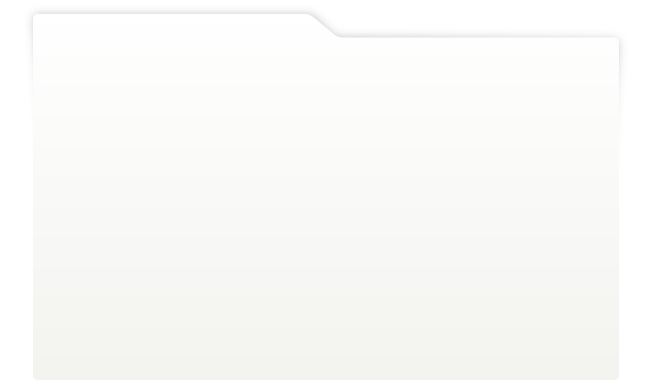
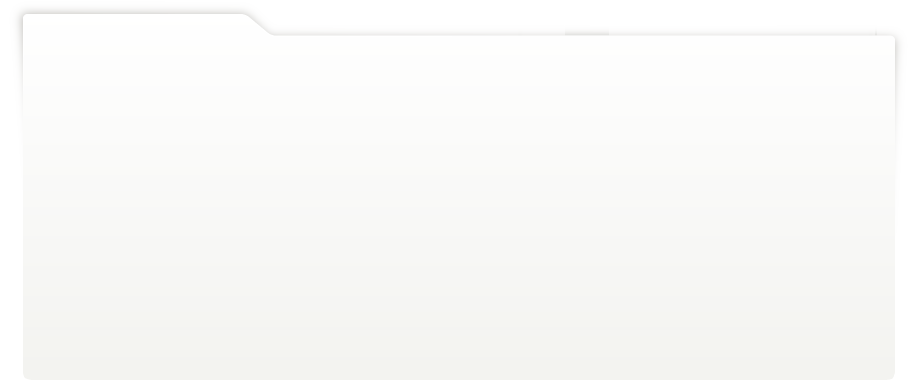
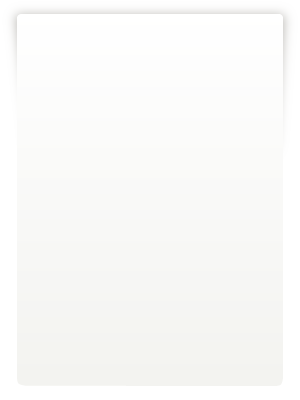
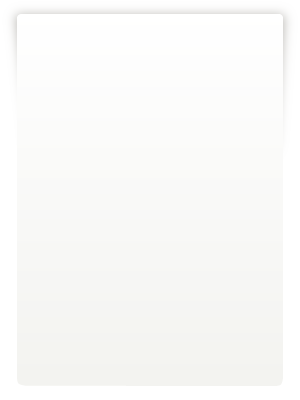
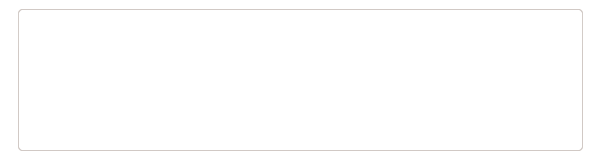
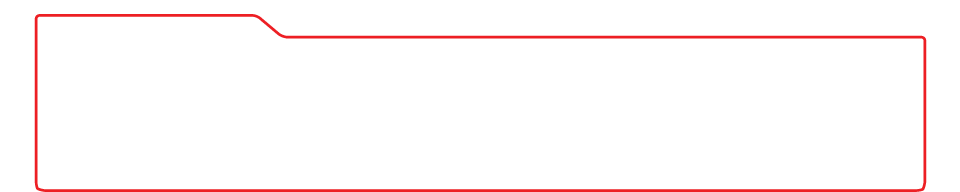
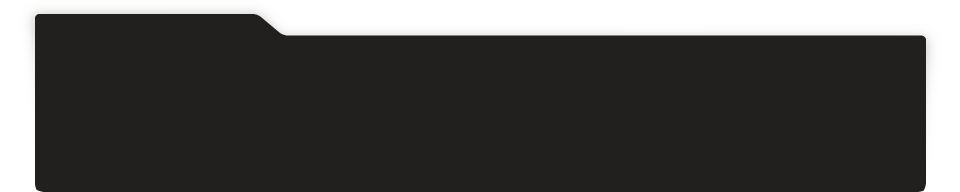
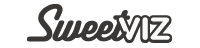
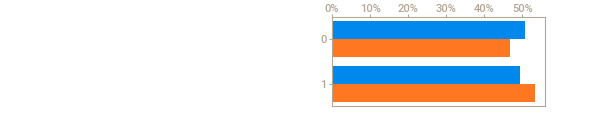
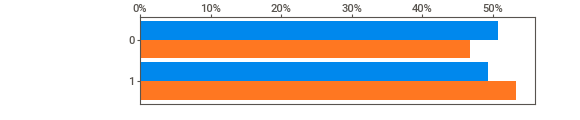
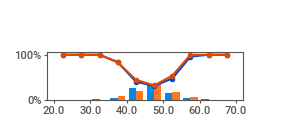
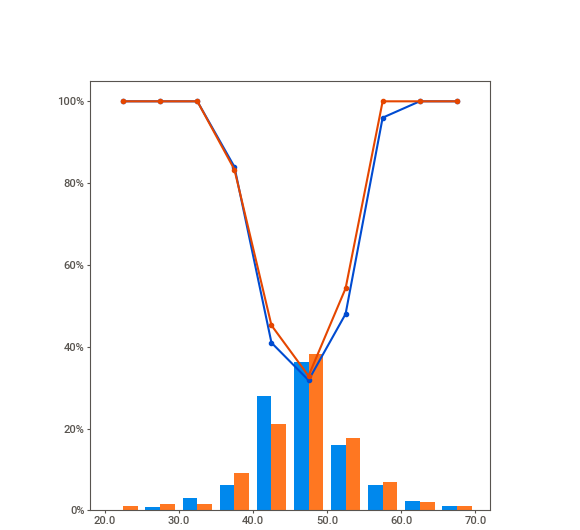
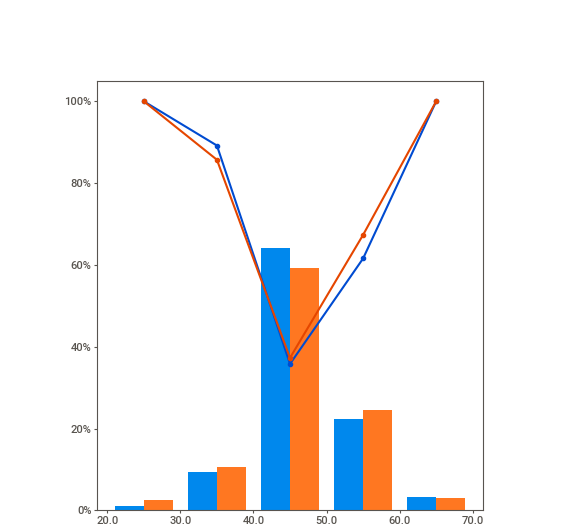
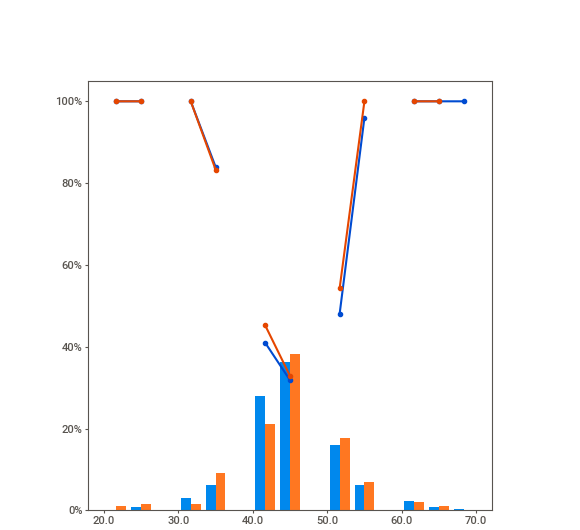
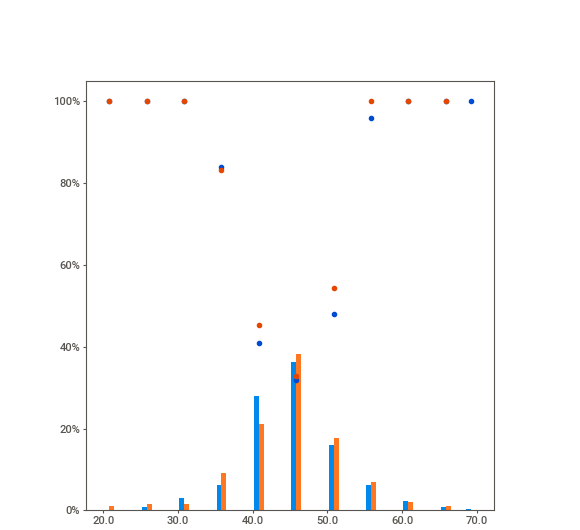
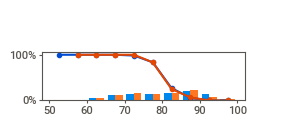
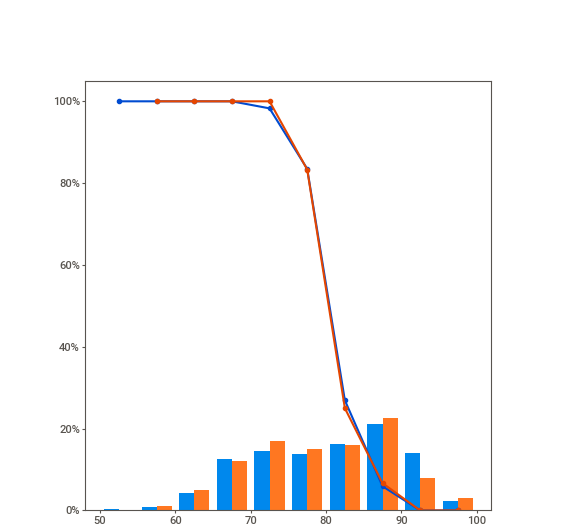
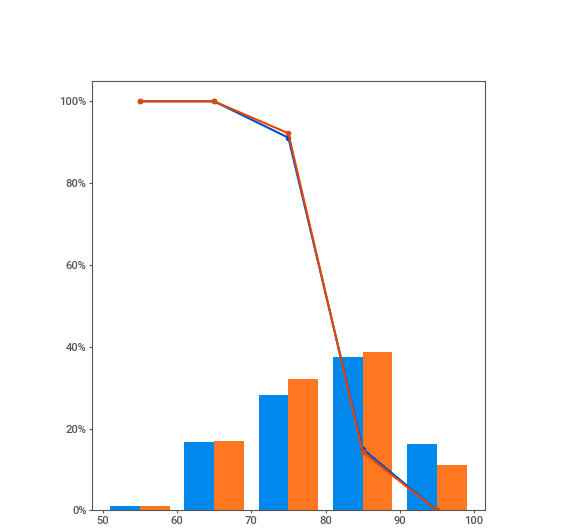
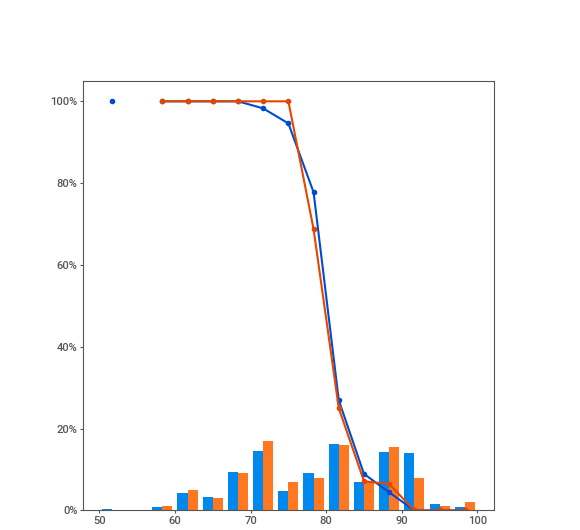
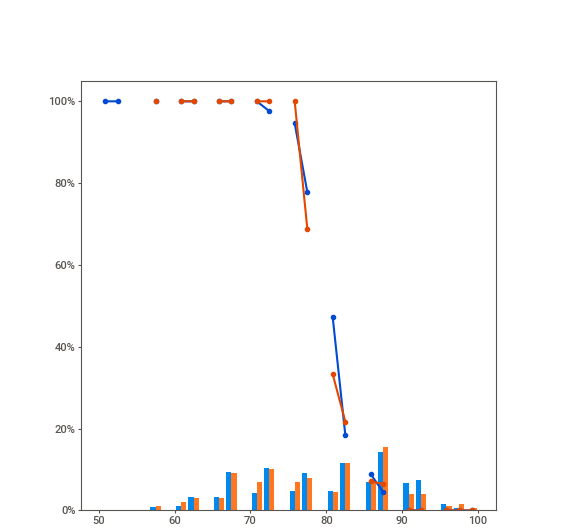
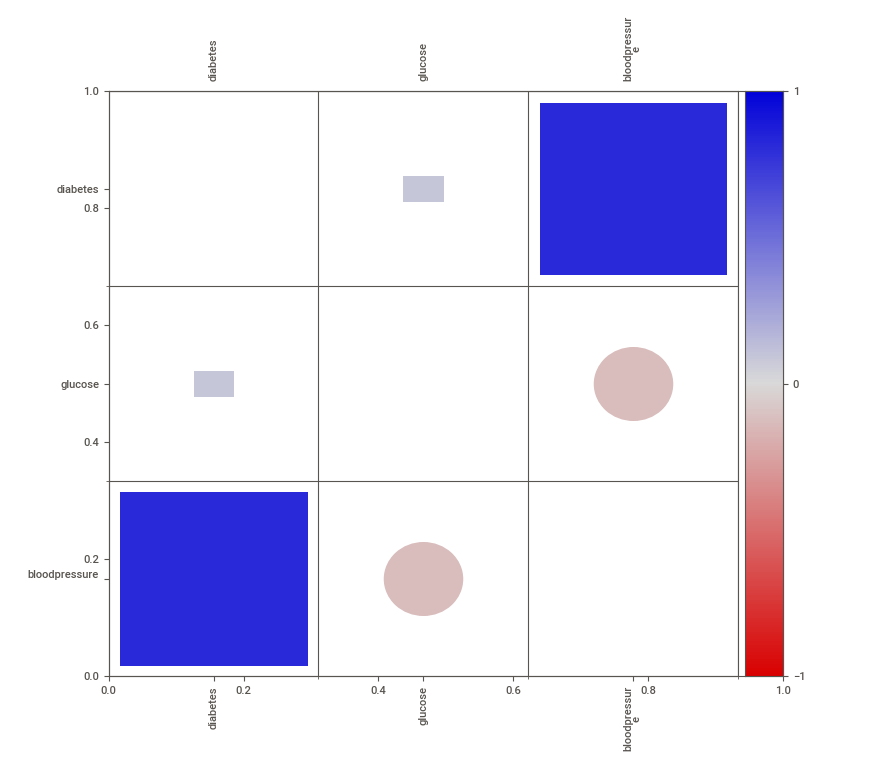
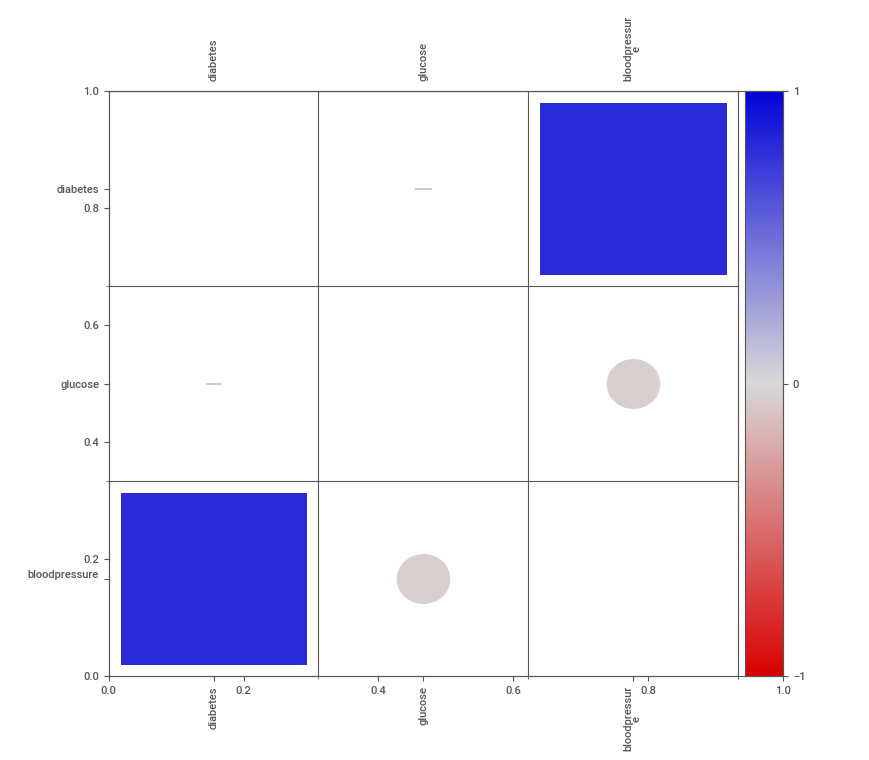


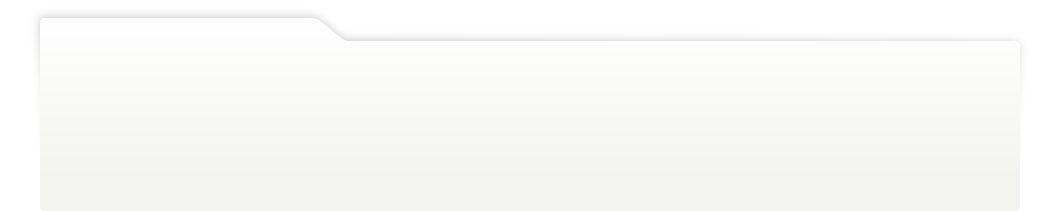
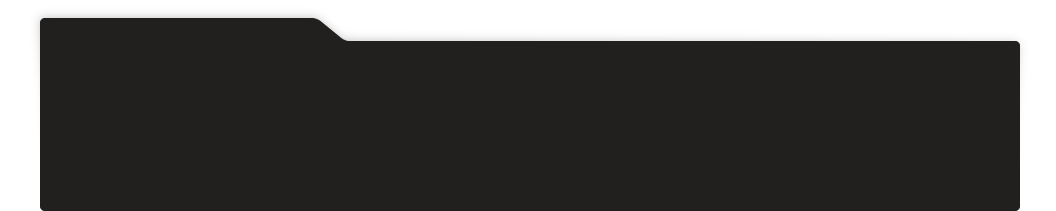
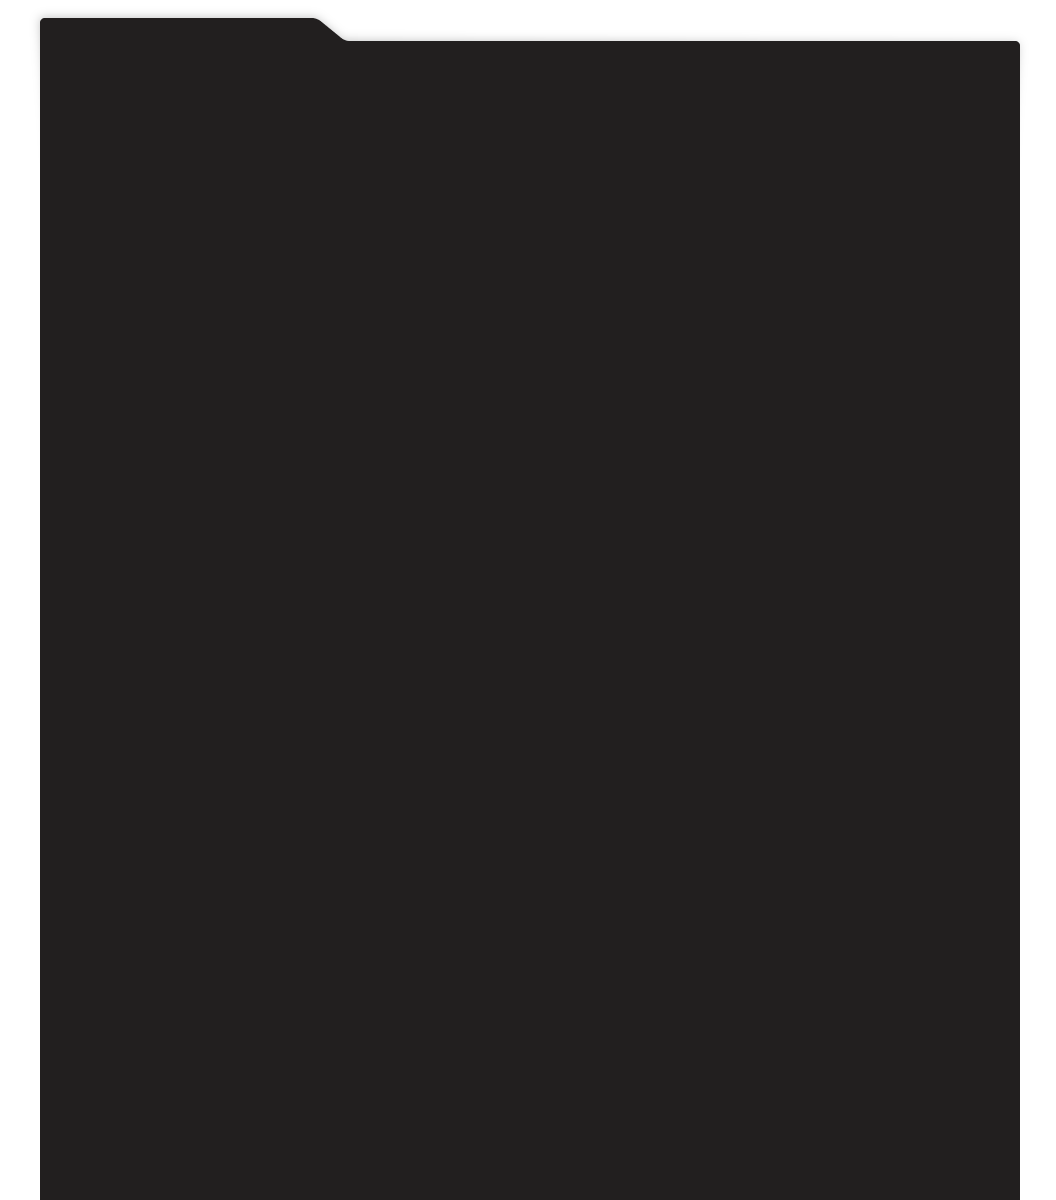
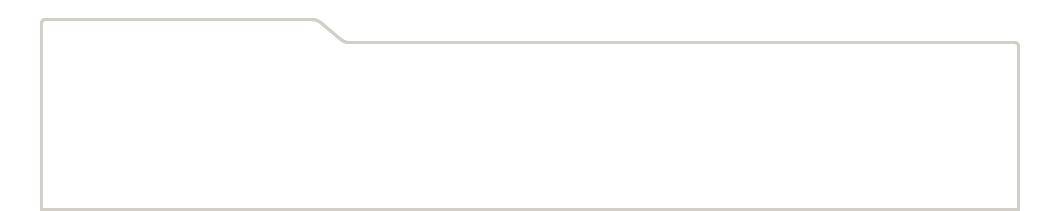
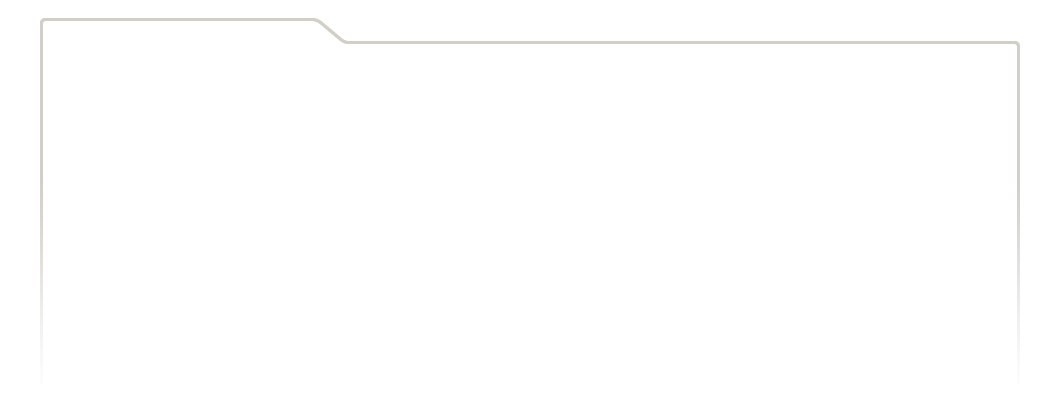
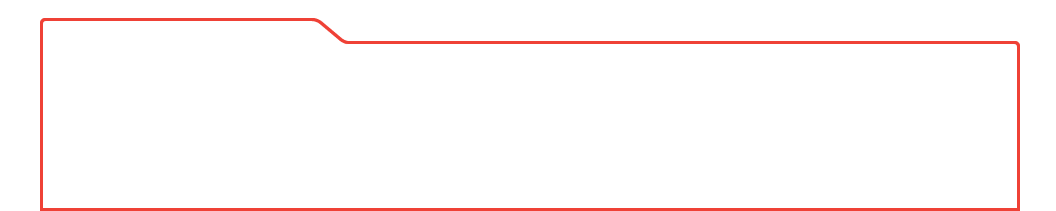
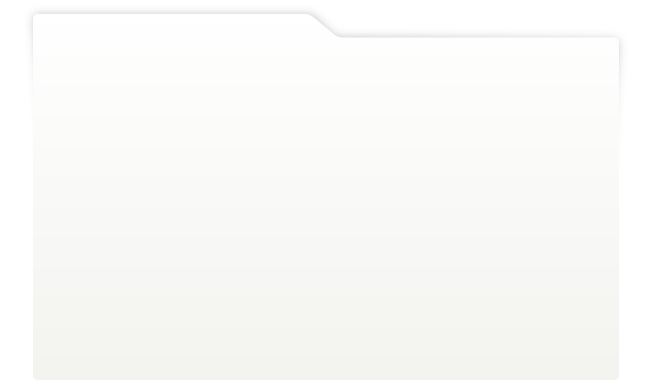
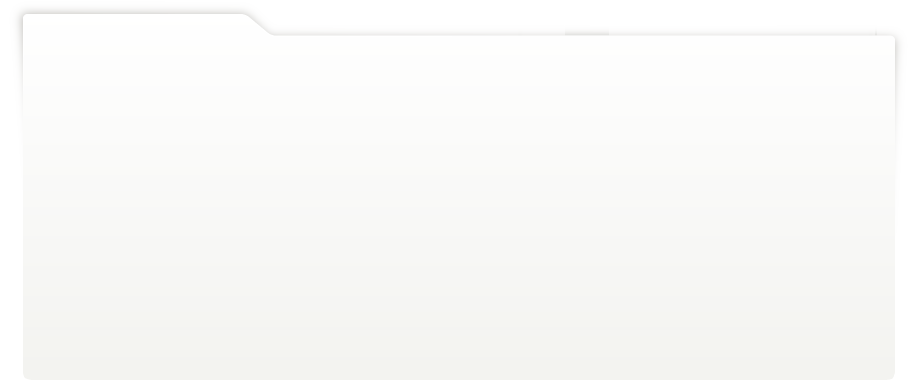
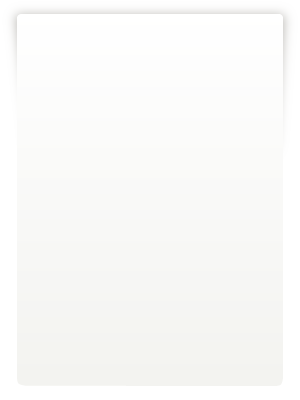
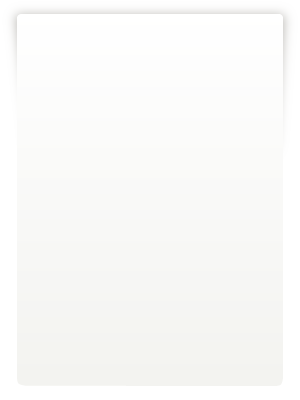
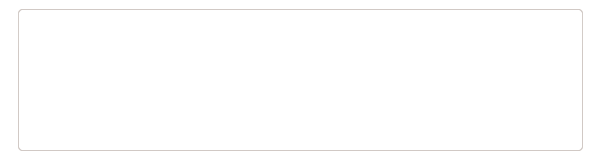
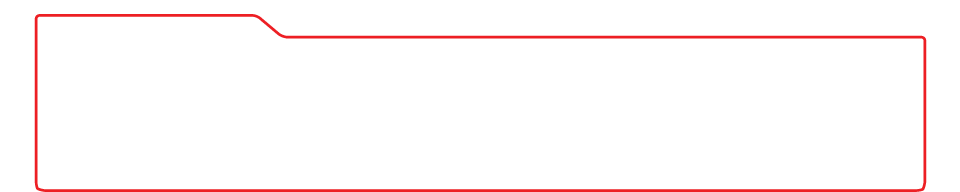
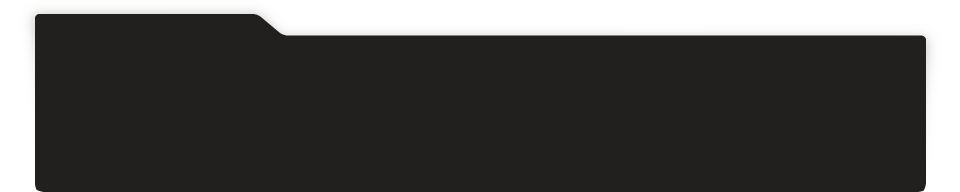
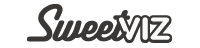
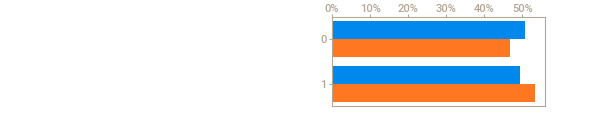
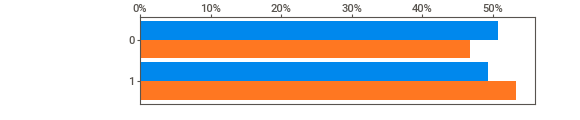
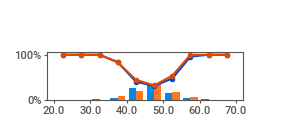
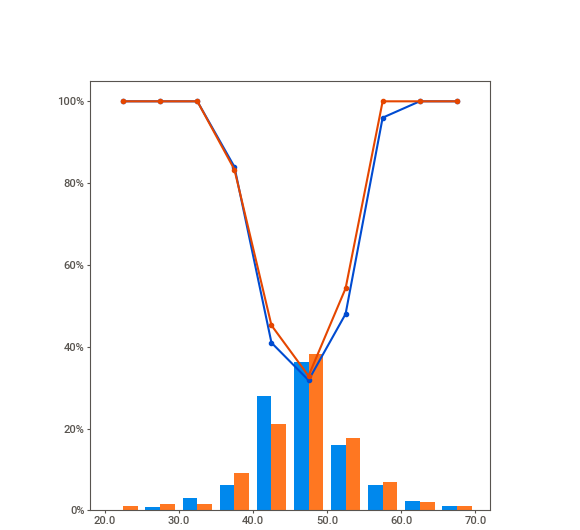
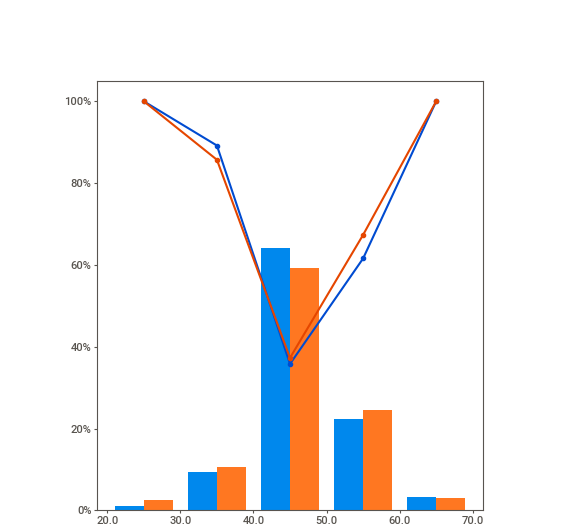
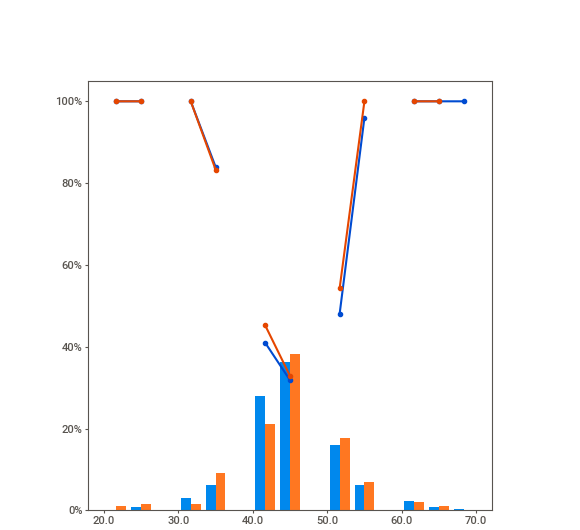
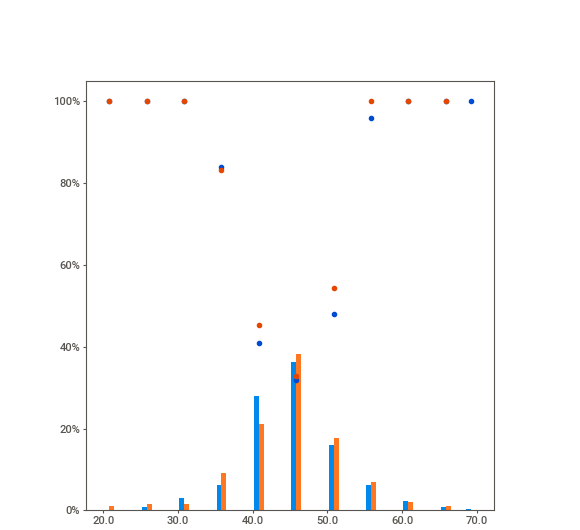
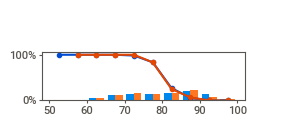
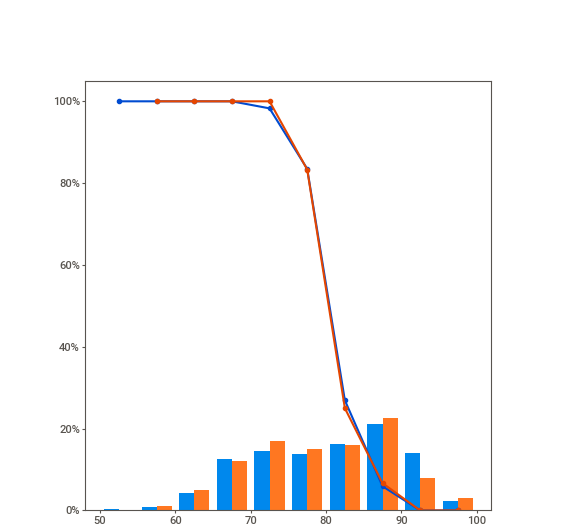
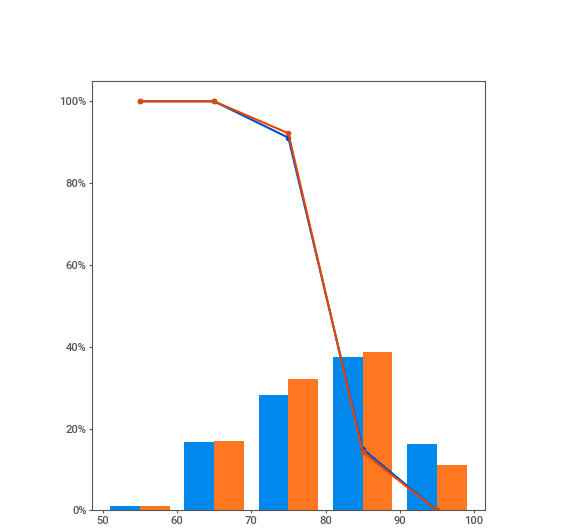
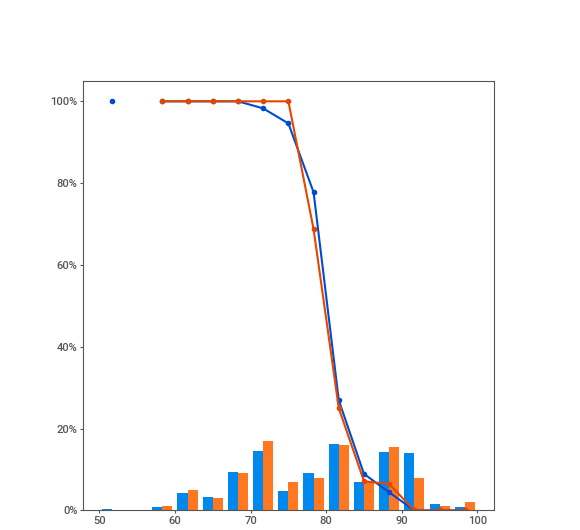
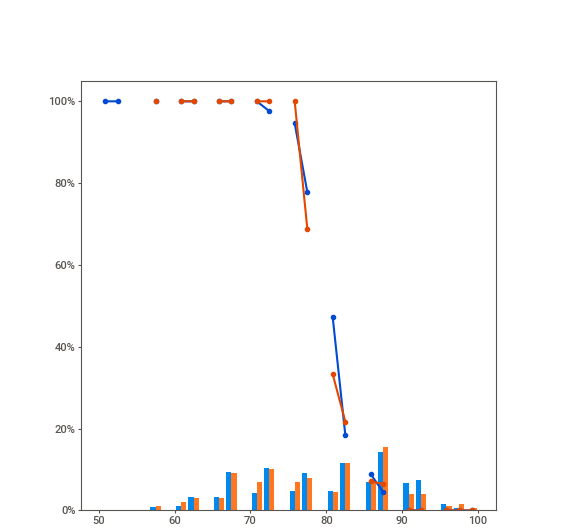
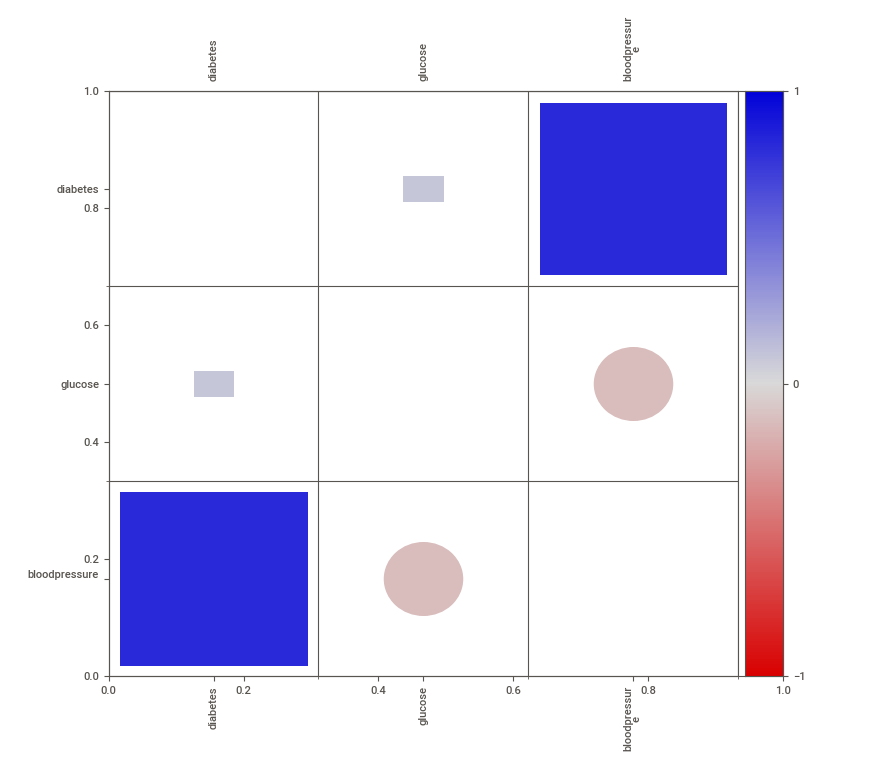
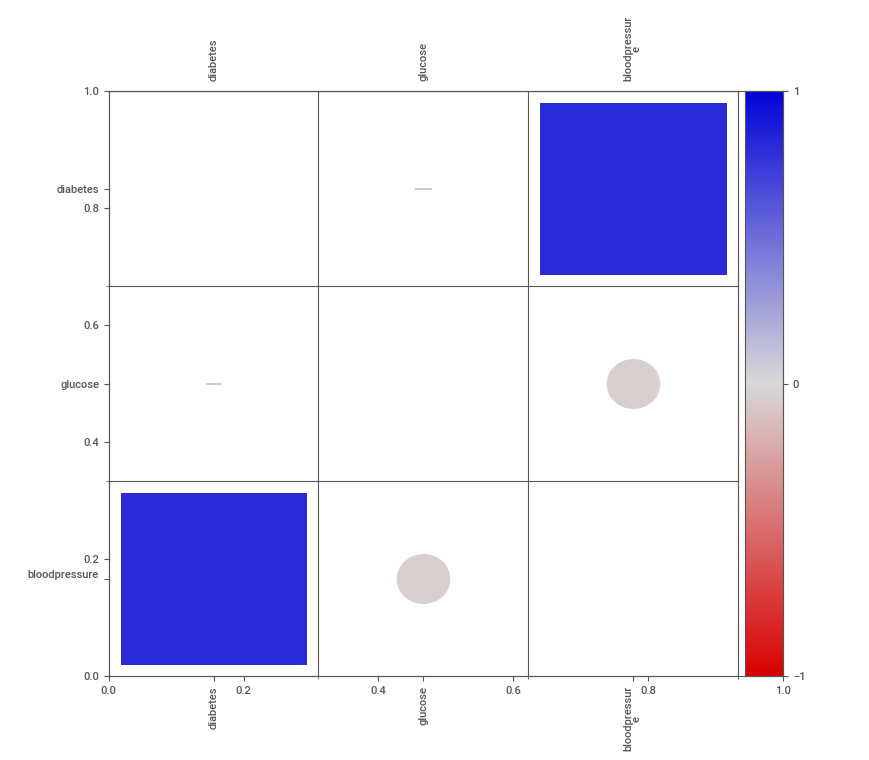

In [11]:
# Using UNPRACTICALLY SMALL windows & scales, just to showcase the two layouts!
comparison_report.show_notebook(layout='widescreen', w=1500, h=300, scale=0.7)
comparison_report.show_notebook(layout='vertical', w=800, h=300, scale=0.7)


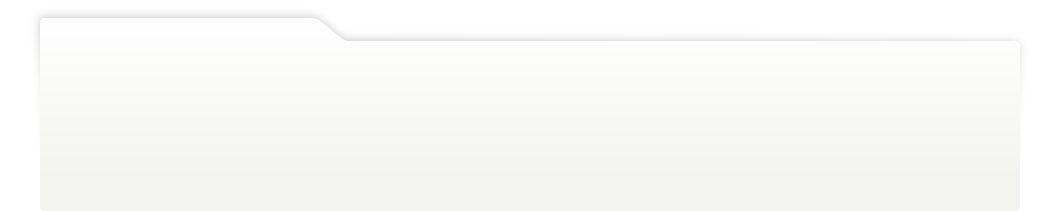
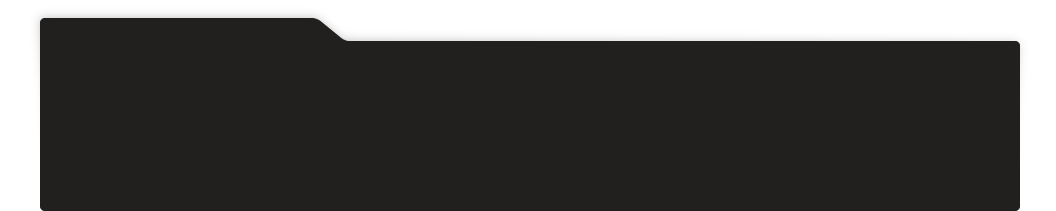
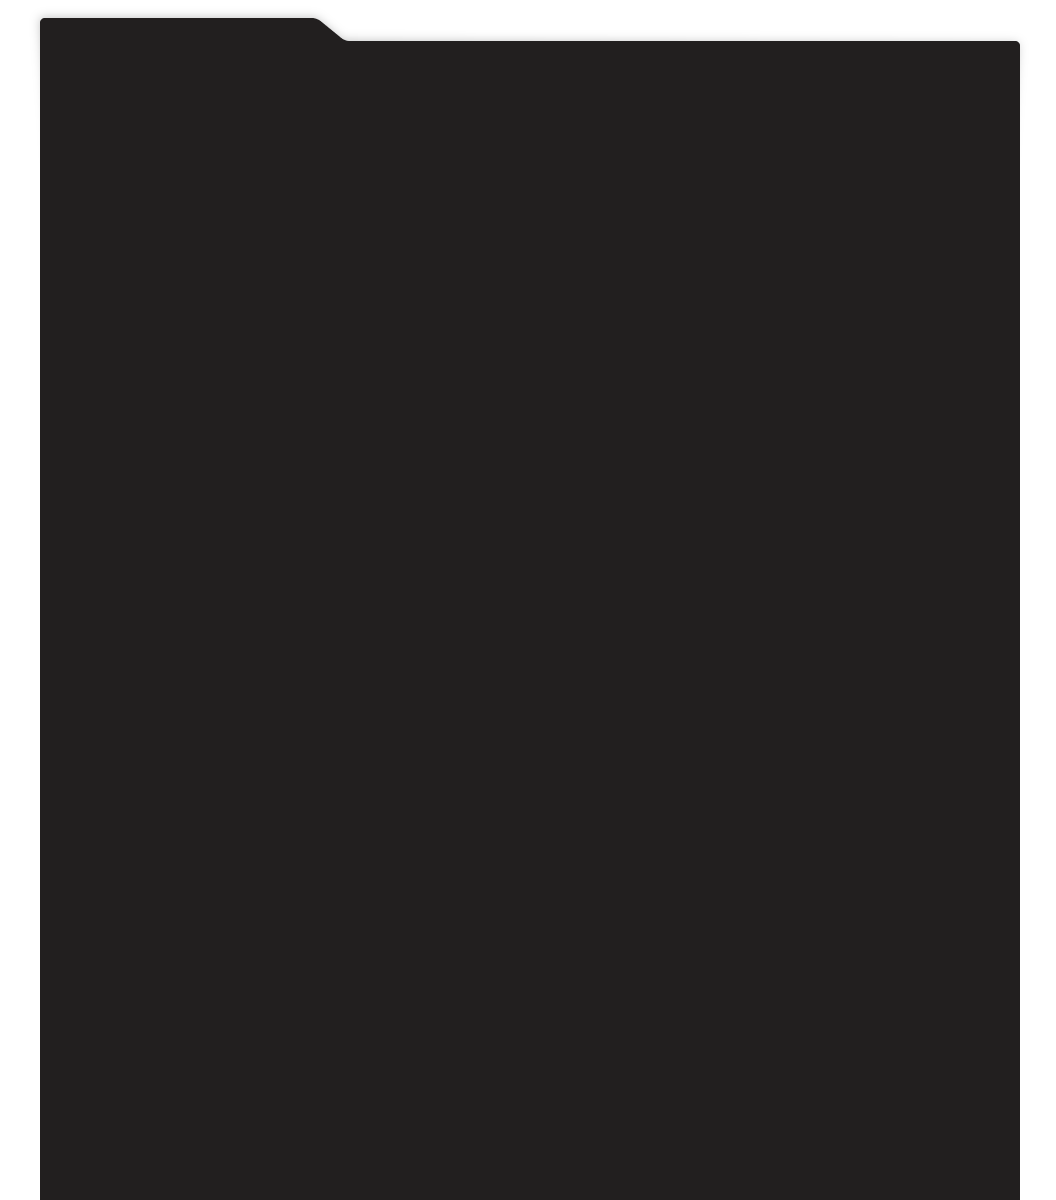
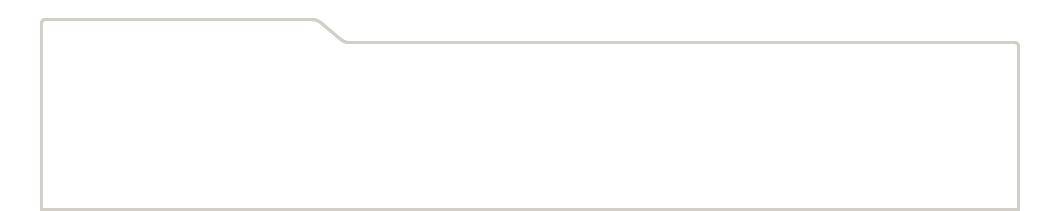
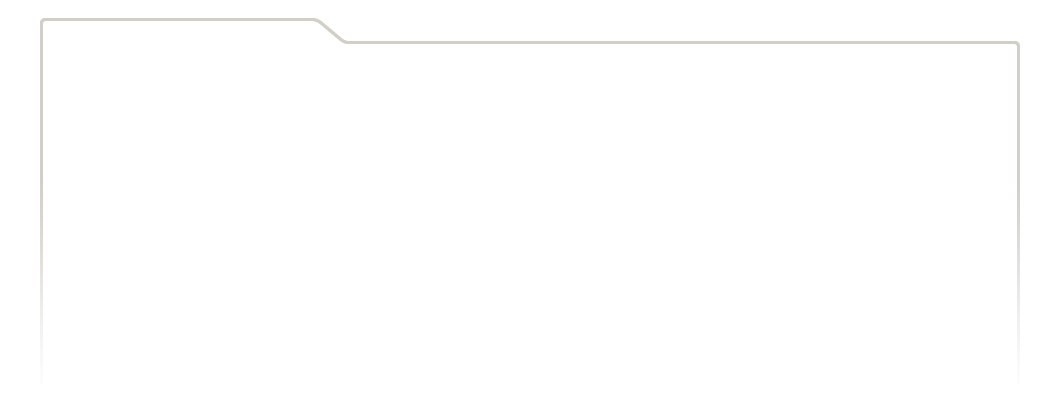
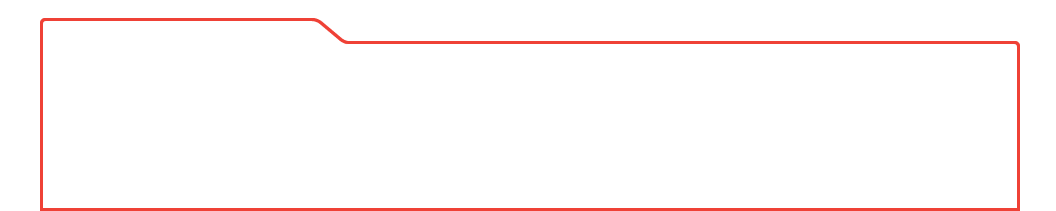
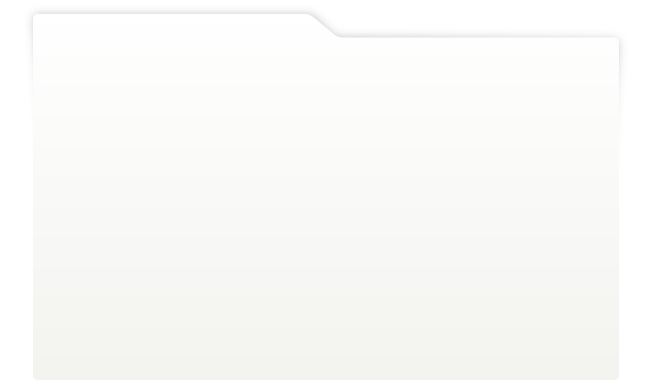
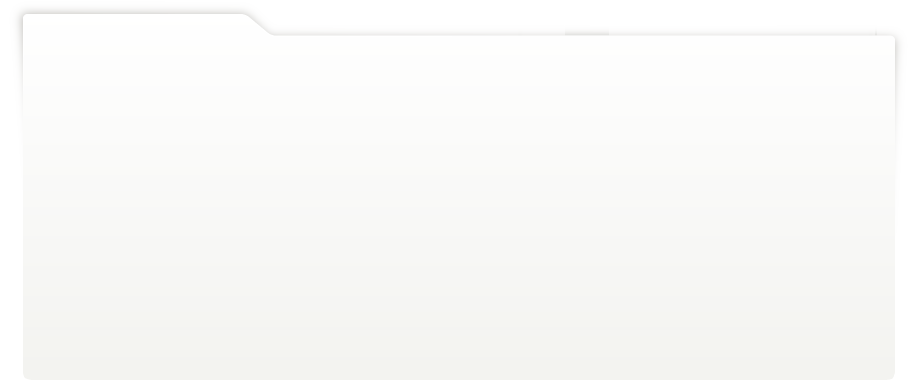
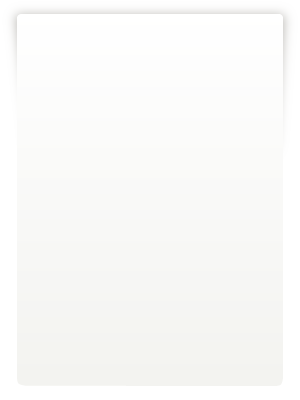
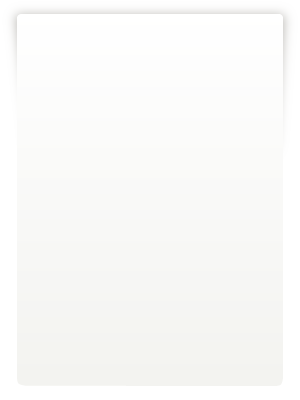
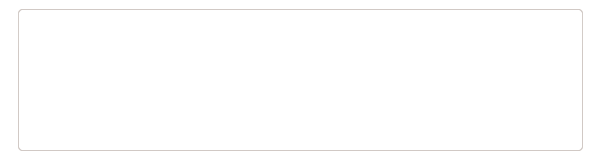
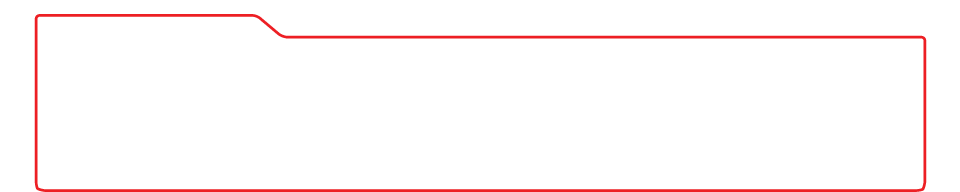
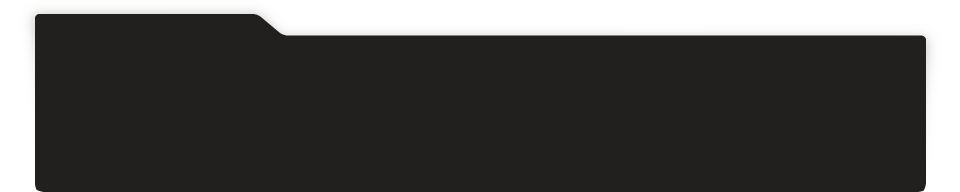
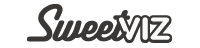
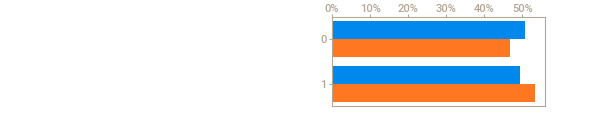
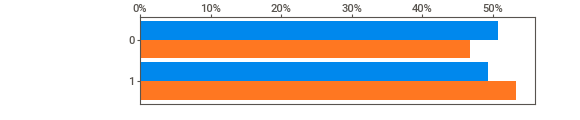
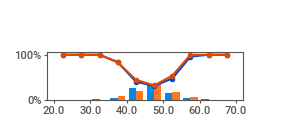
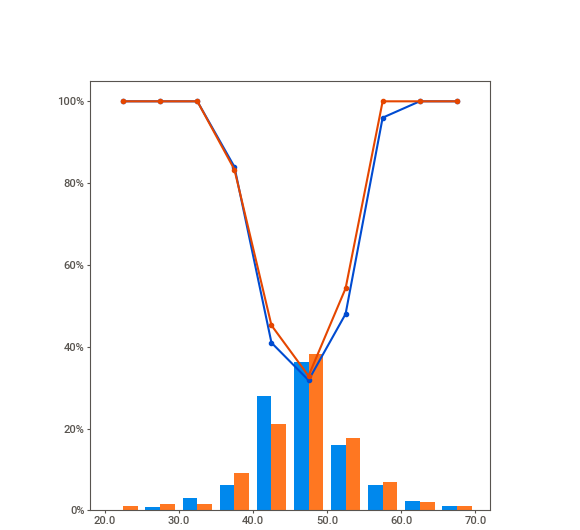
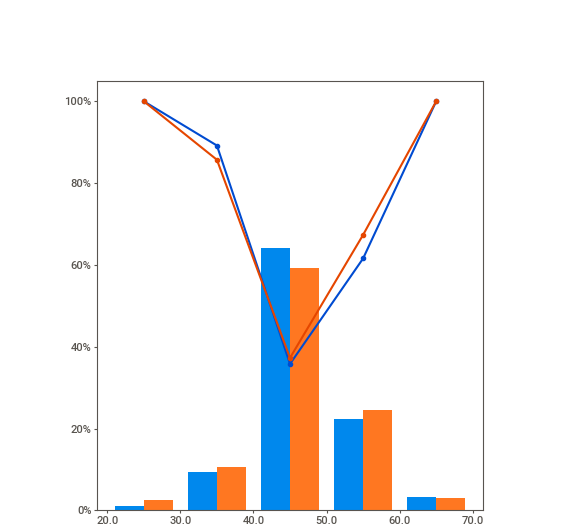
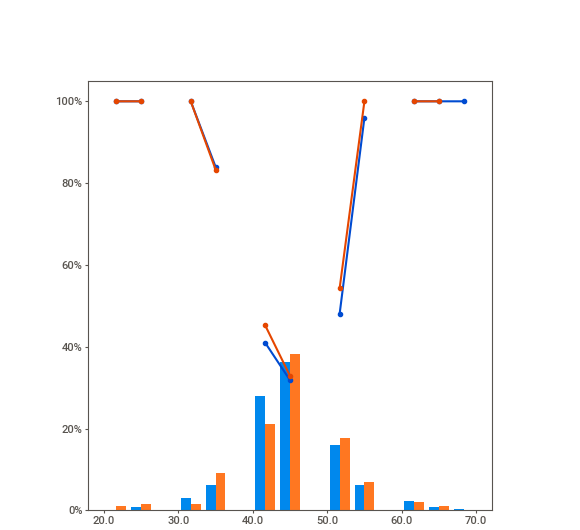
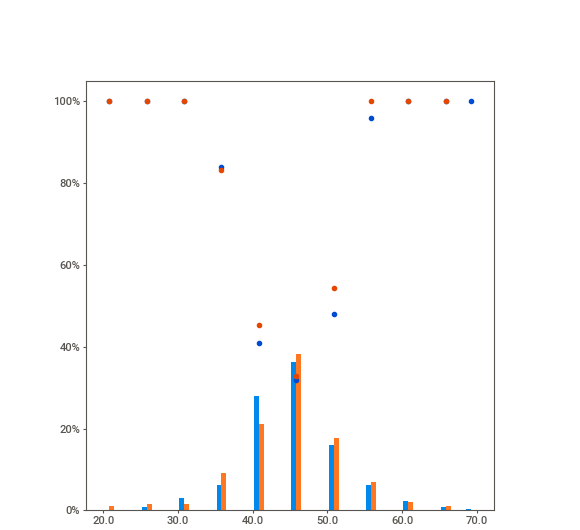
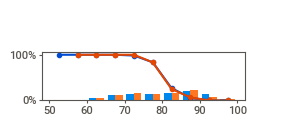
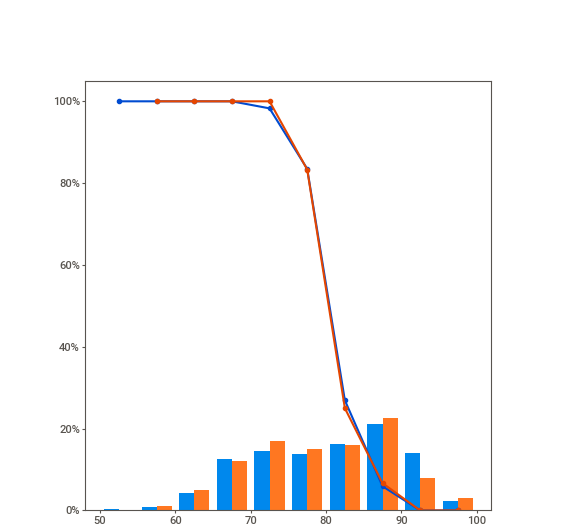
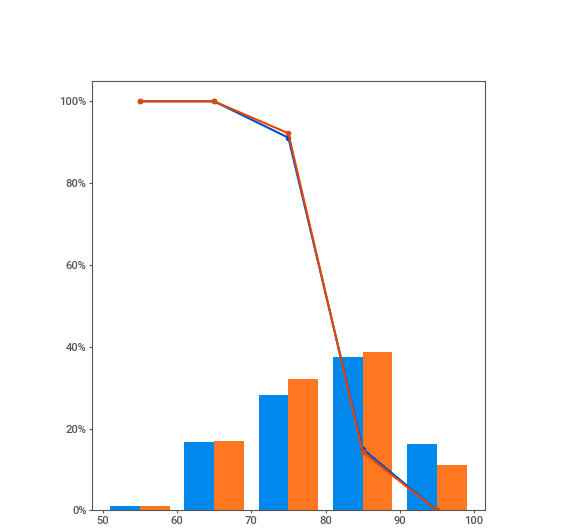
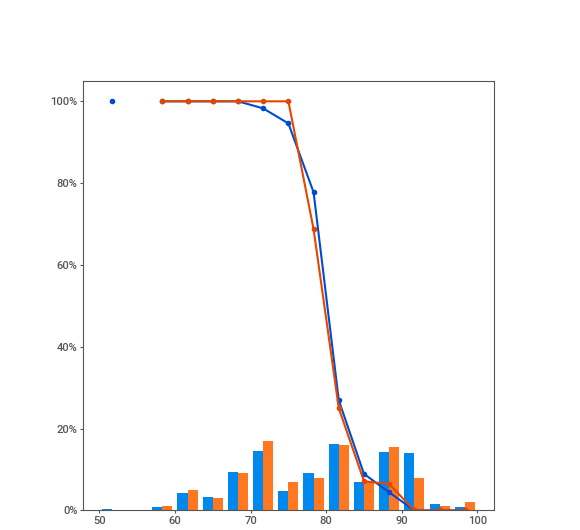
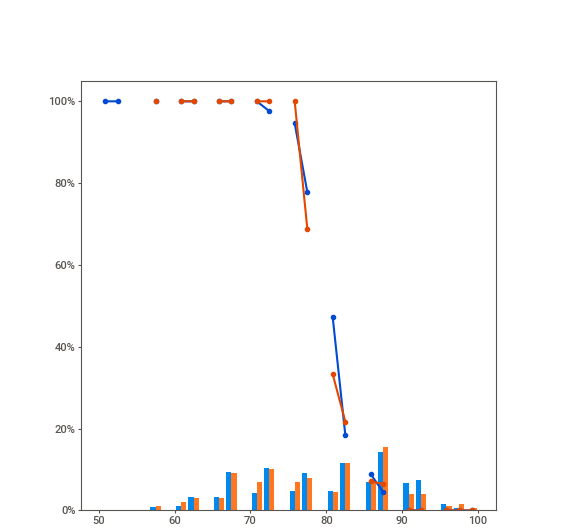
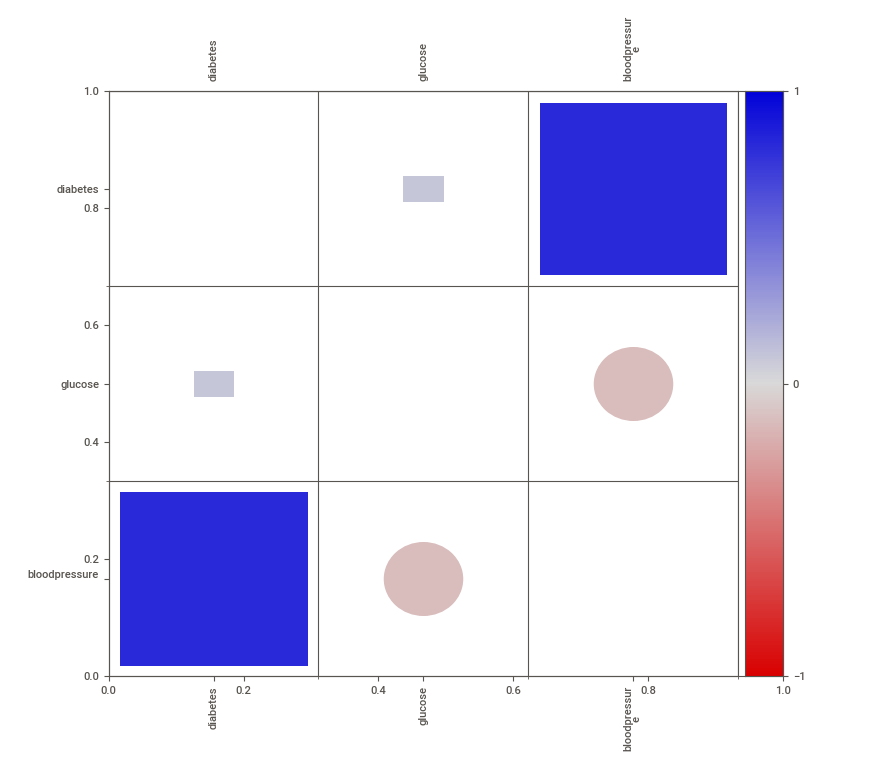
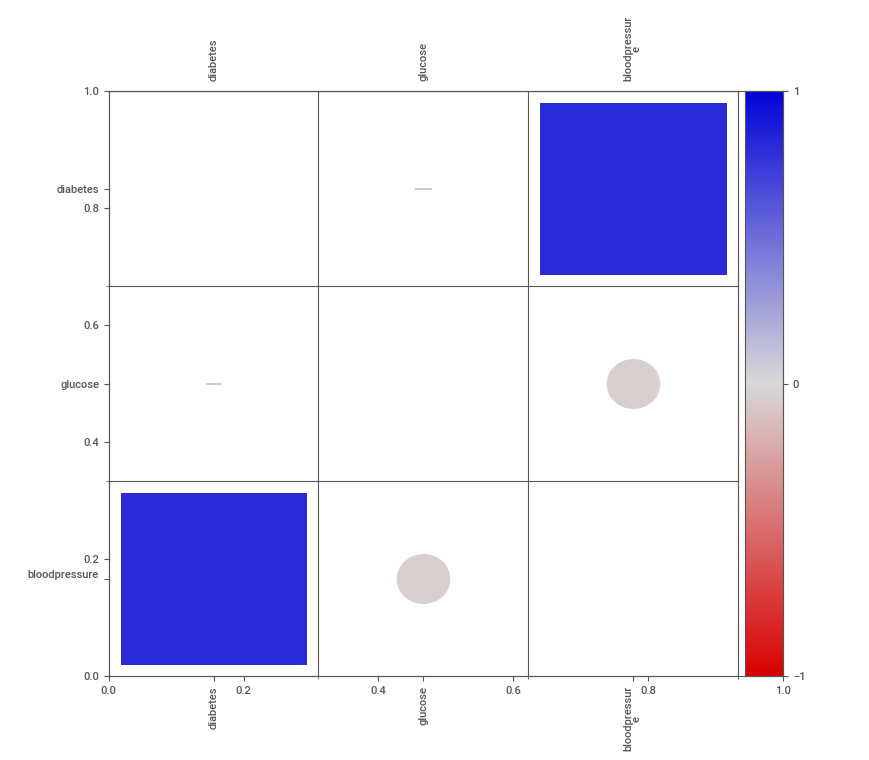

In [12]:
# Compact window, with compact report!
comparison_report.show_notebook(w=900, h=700, scale=0.8)

                                             |          | [  0%]   00:00 -> (? left)


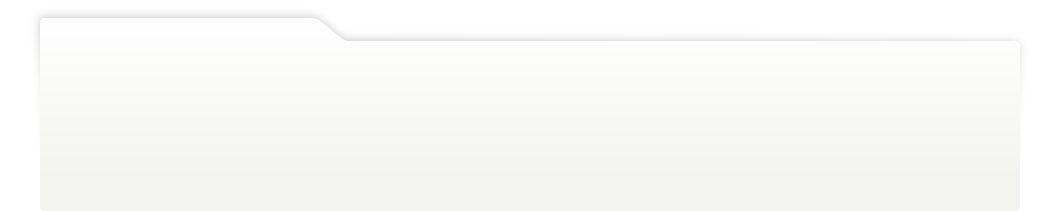
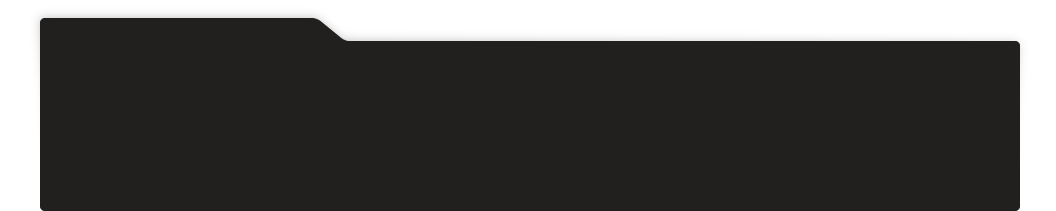
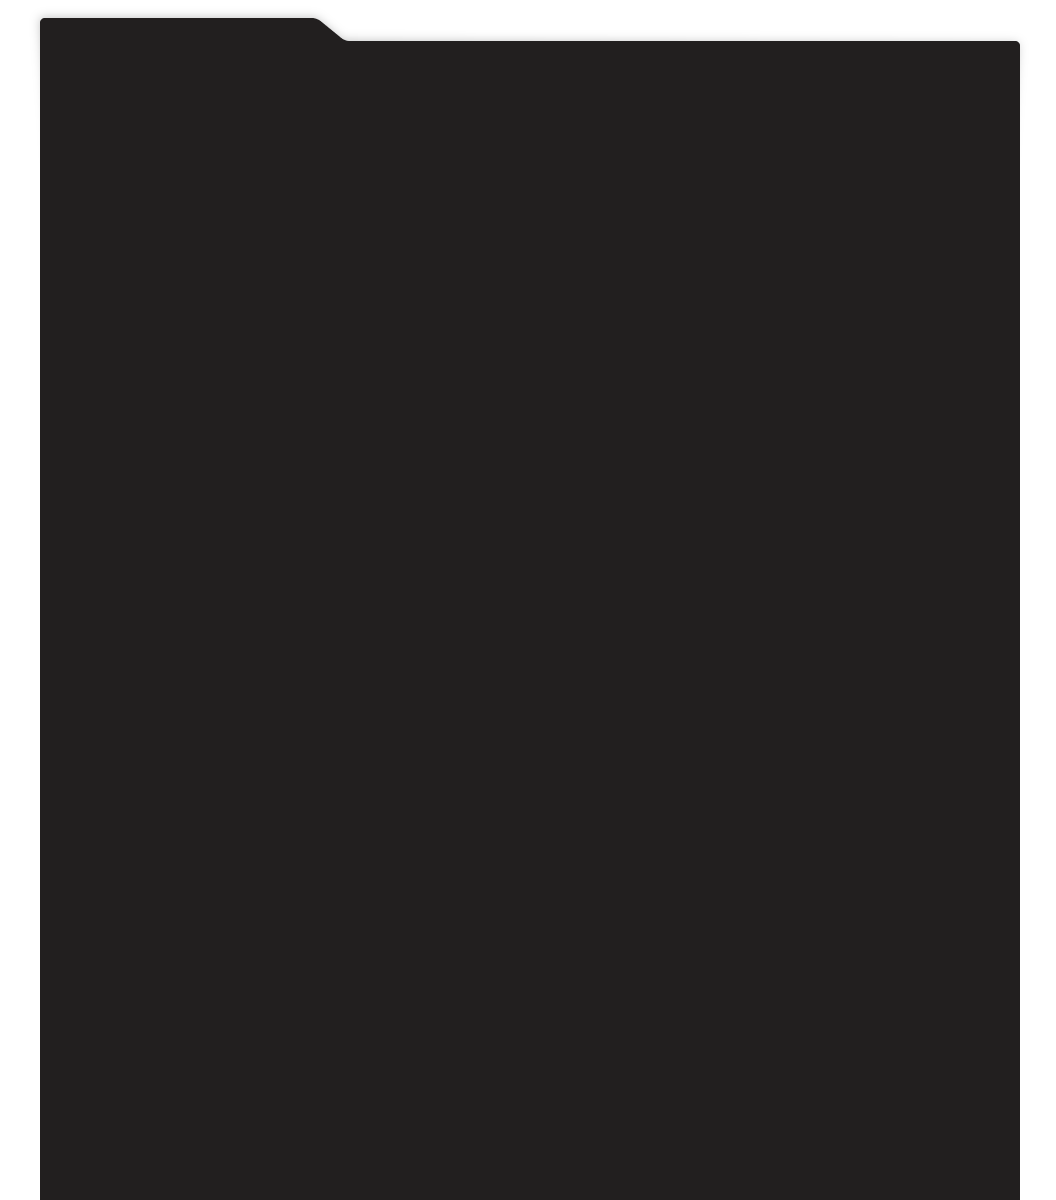
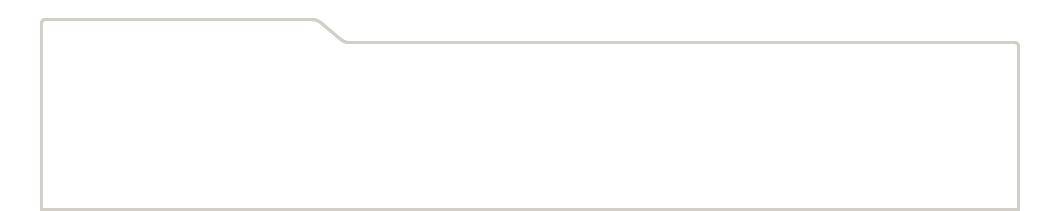
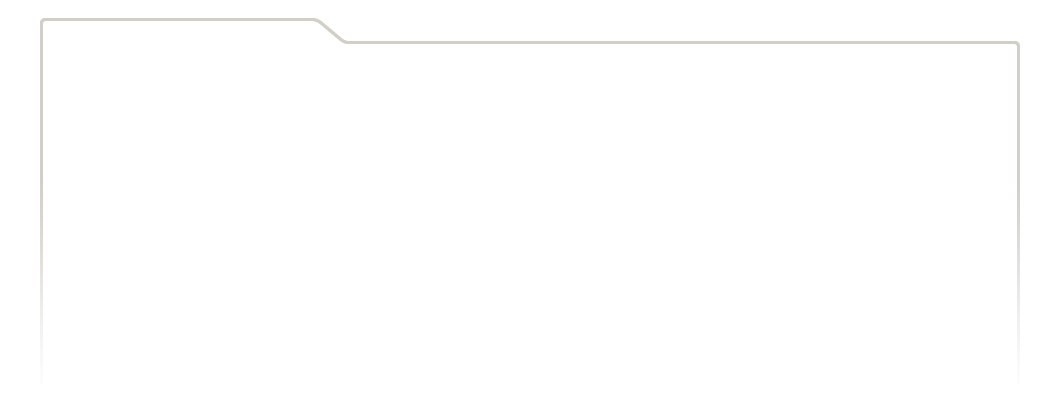
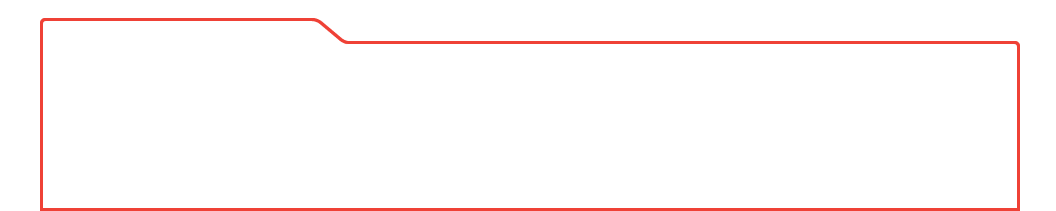
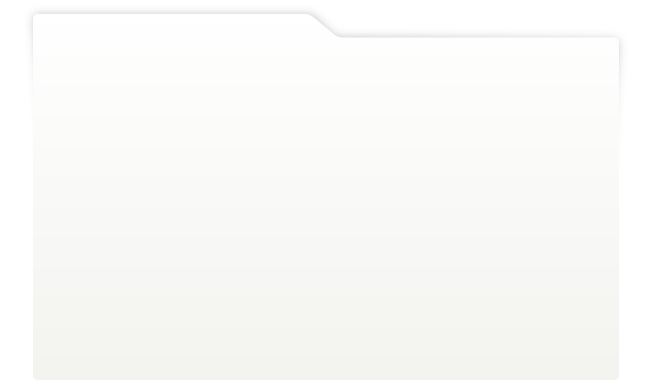
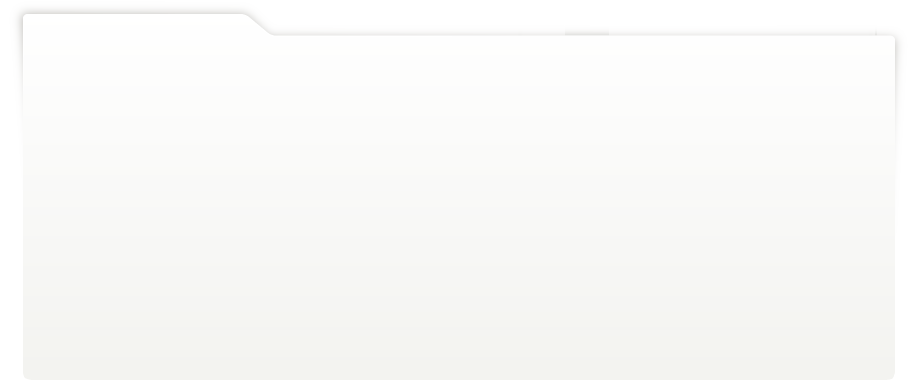
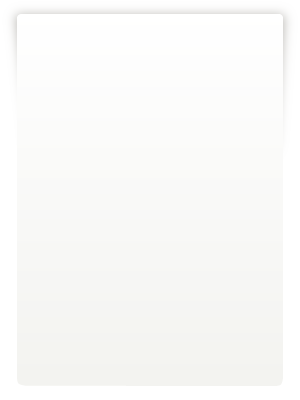
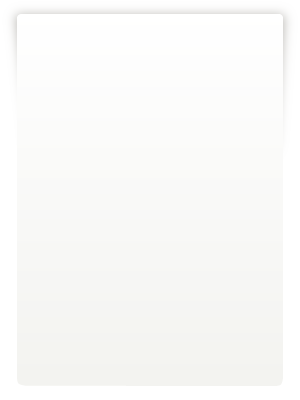
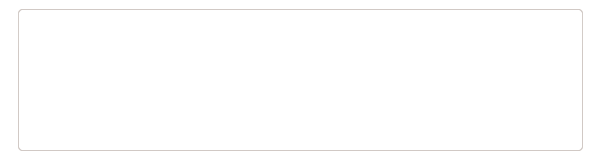
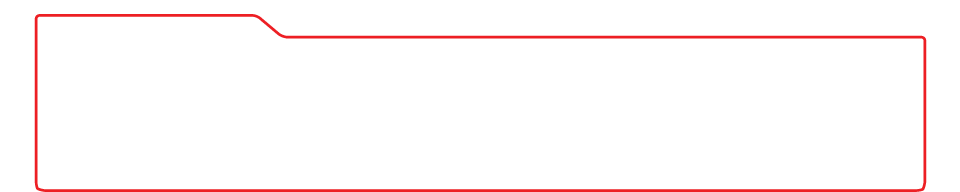
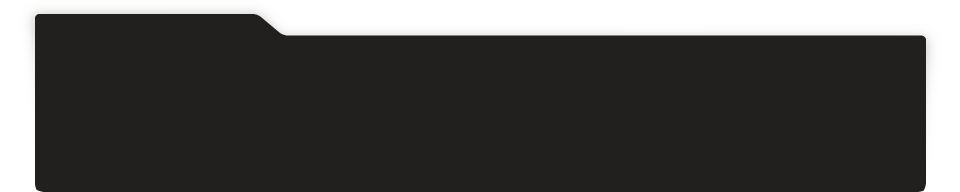
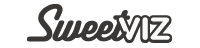
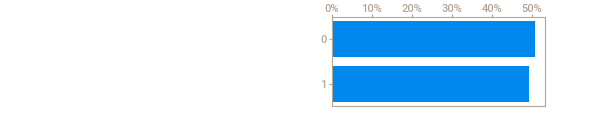
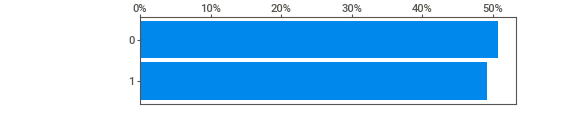
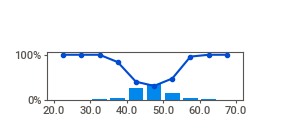
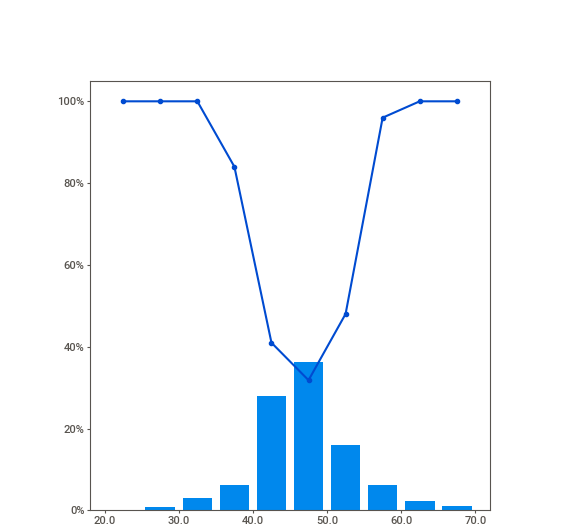
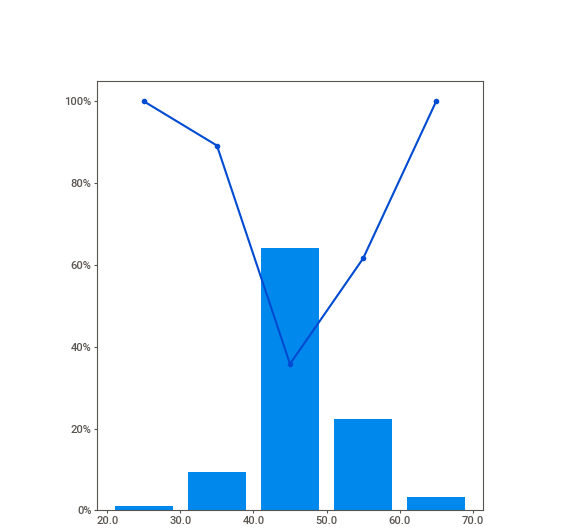
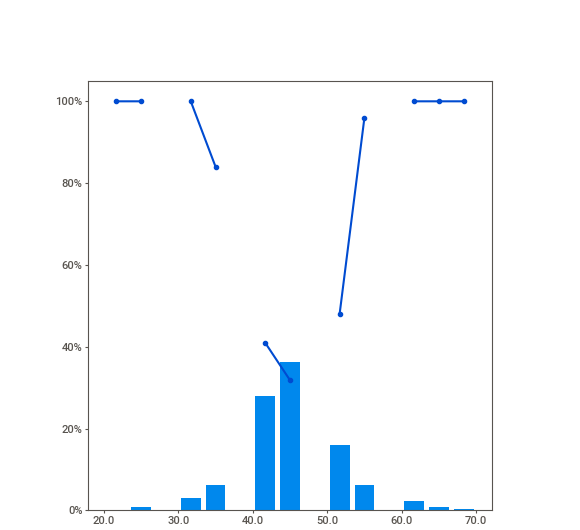
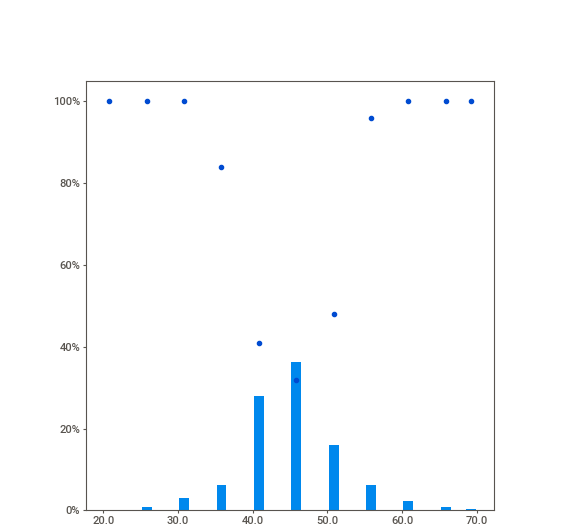
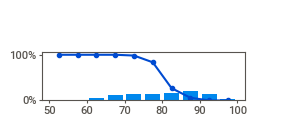
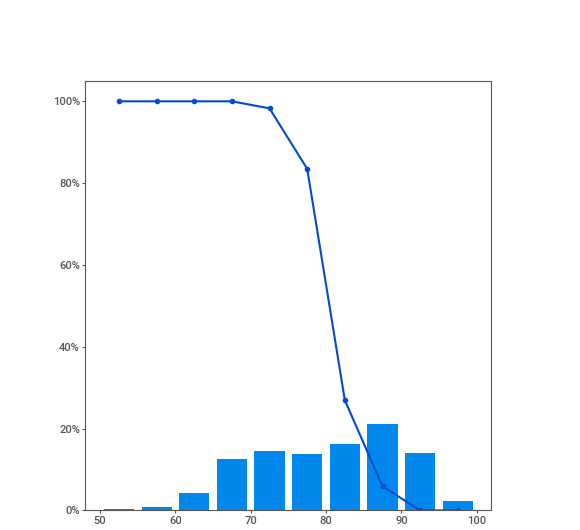
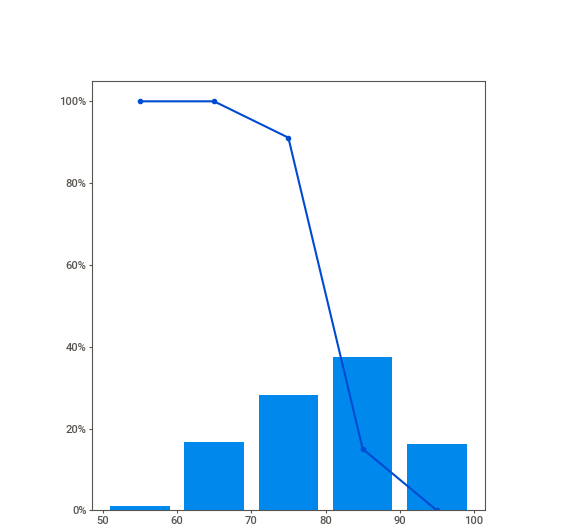
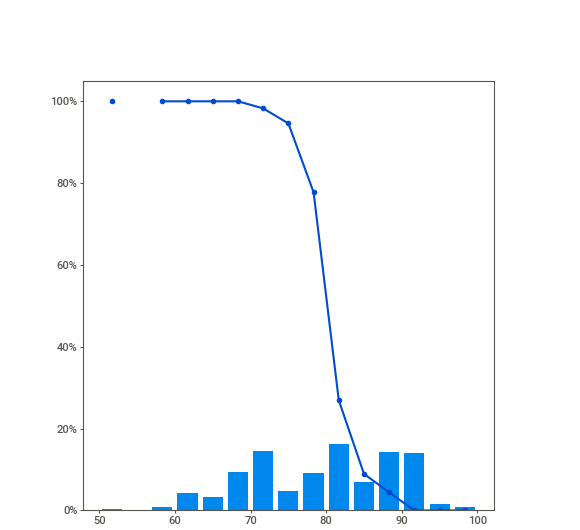
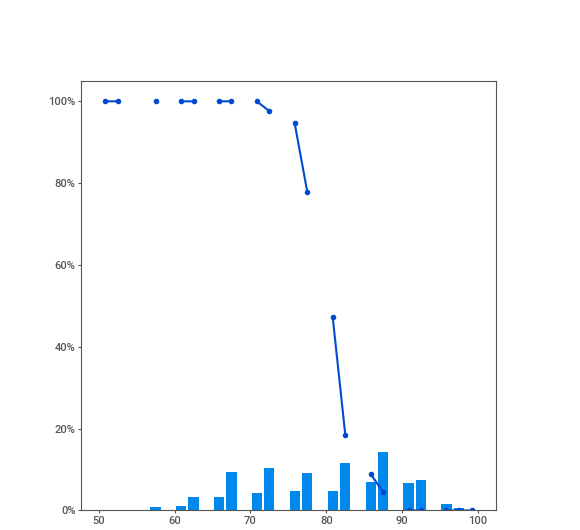
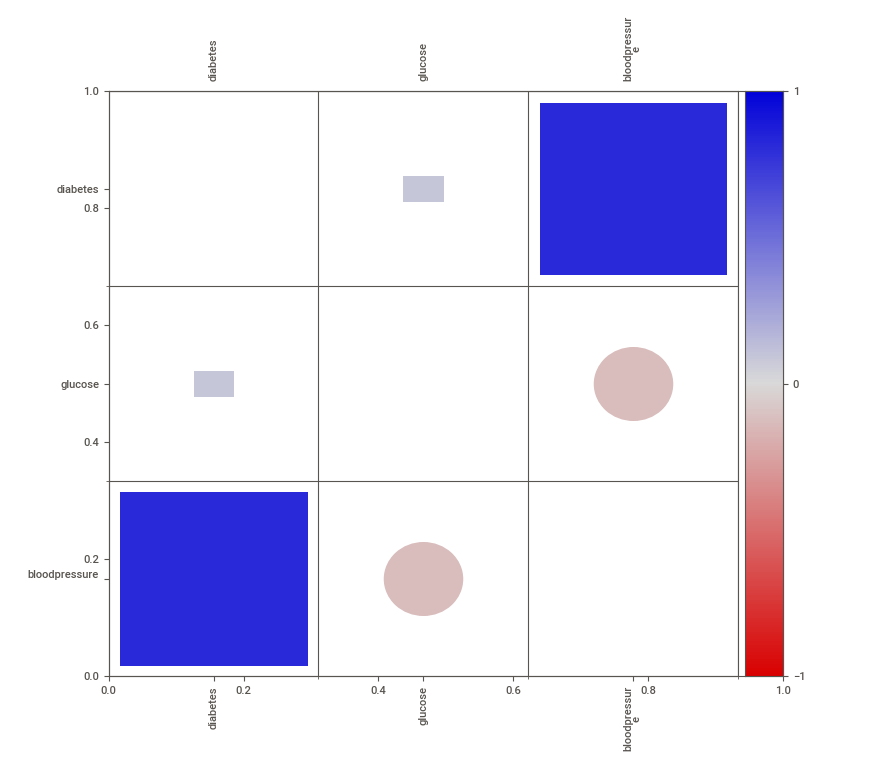
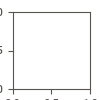

In [15]:
feature_config = sv.FeatureConfig()
analyze_report = sv.analyze([train_df, 'Train'],
                            'diabetes', feature_config)
analyze_report.show_notebook(w=900, h=450, scale=0.8)

                                             |          | [  0%]   00:00 -> (? left)


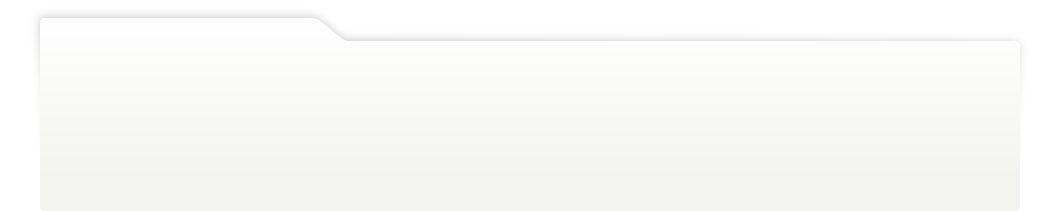
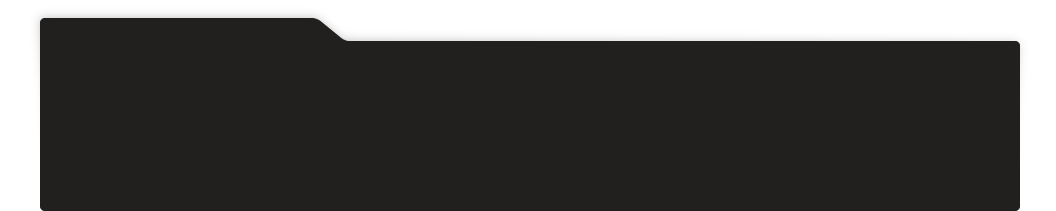
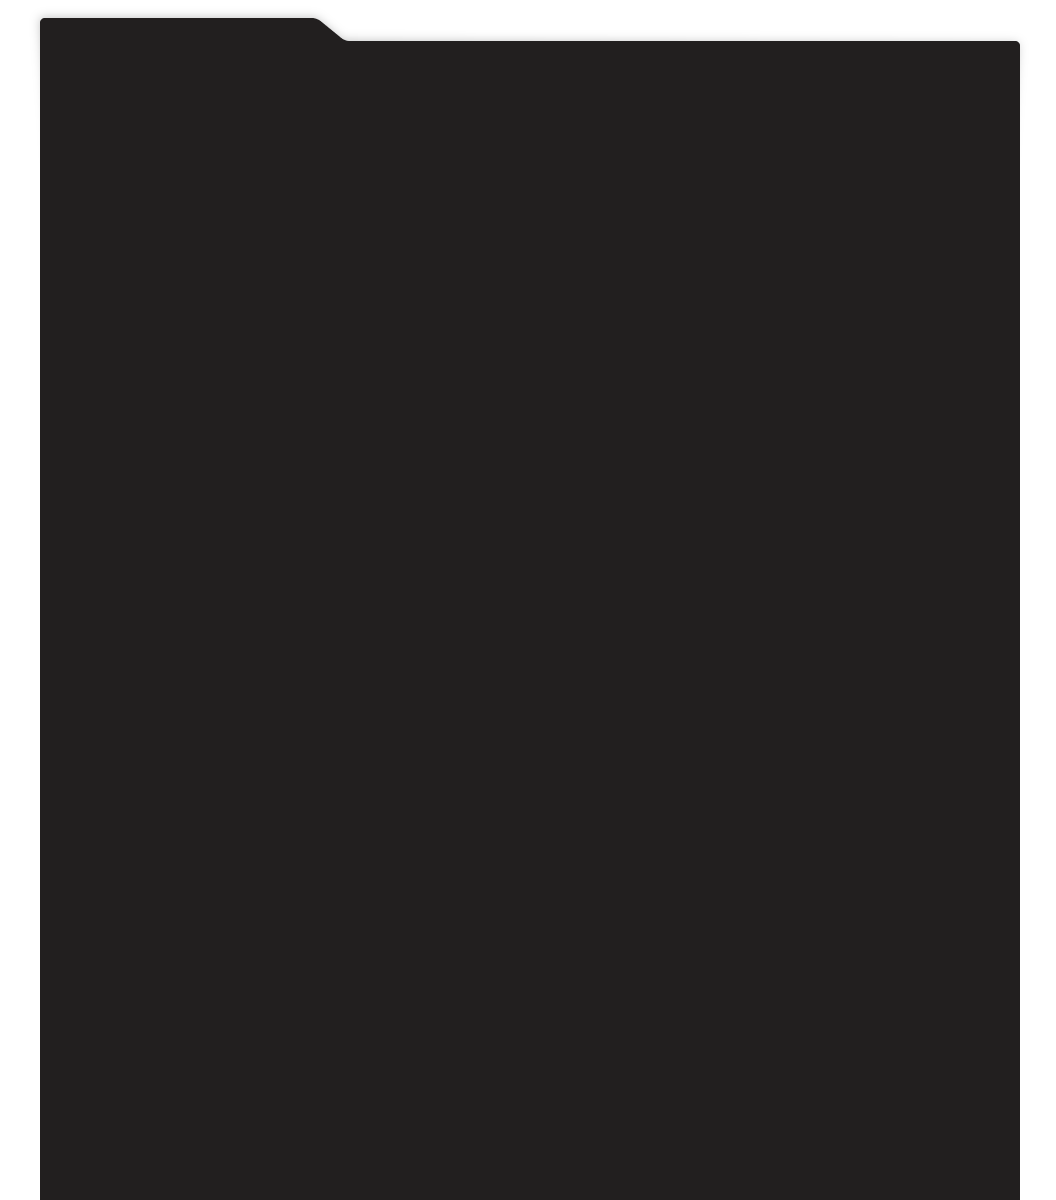
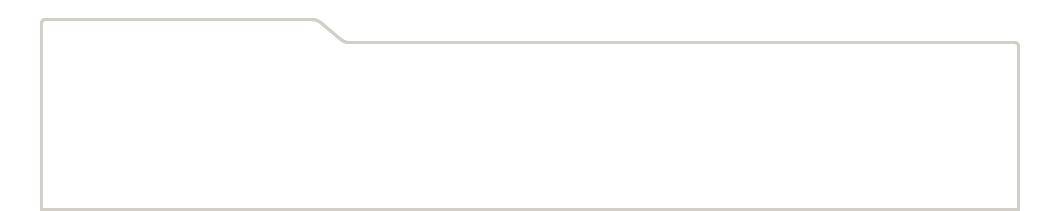
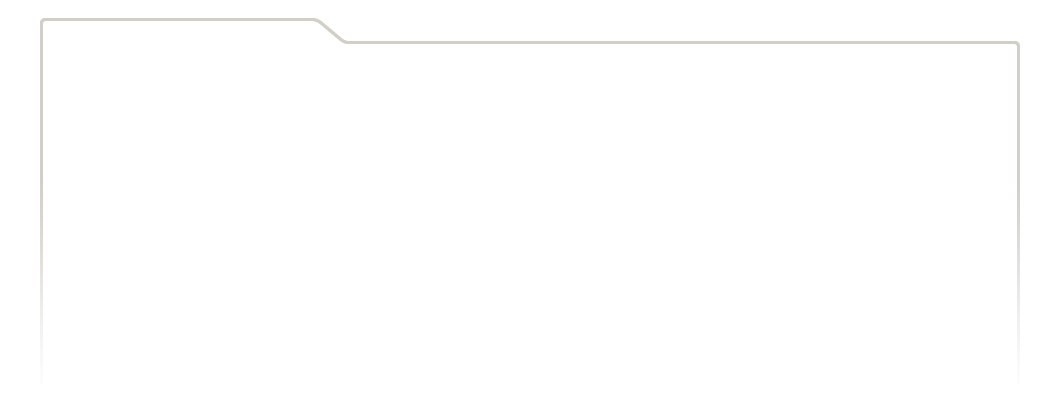
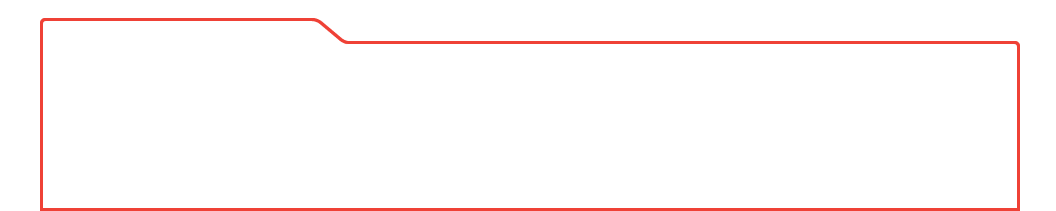
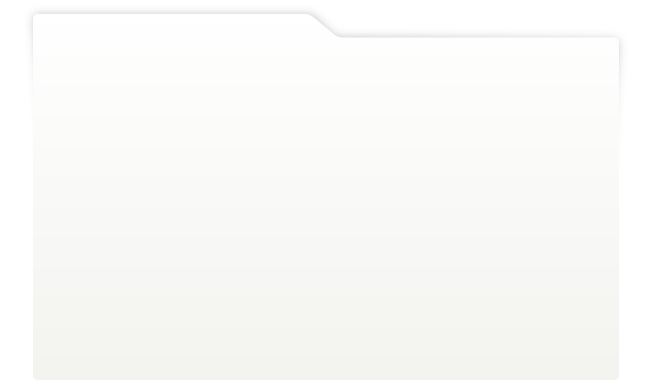
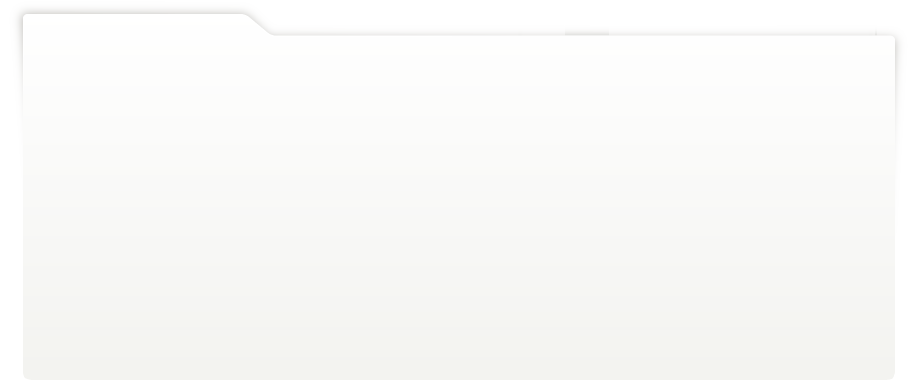
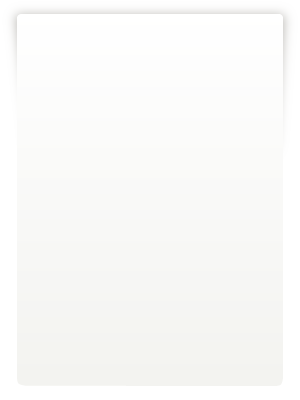
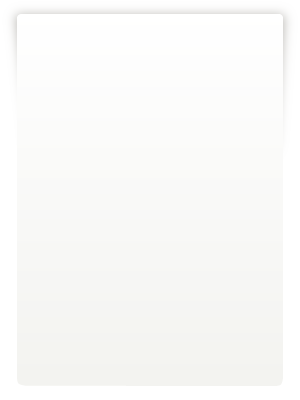
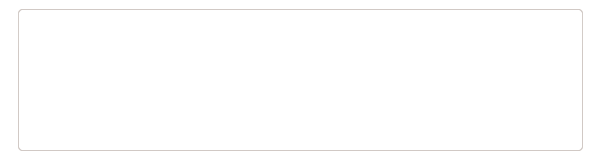
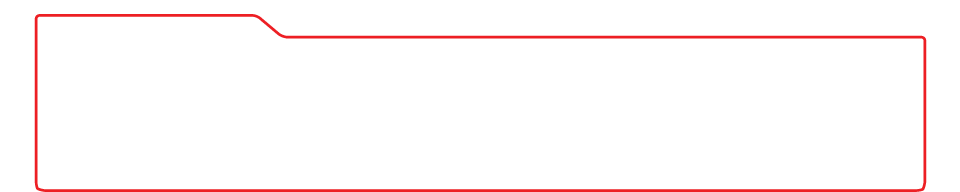
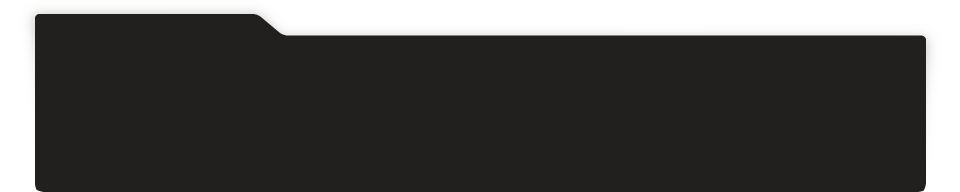
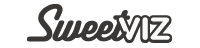
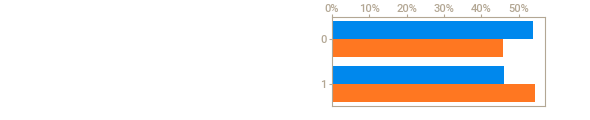
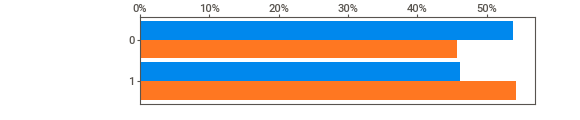
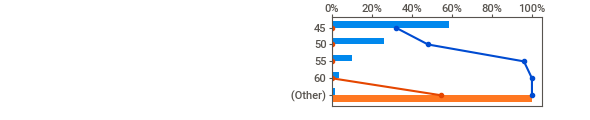
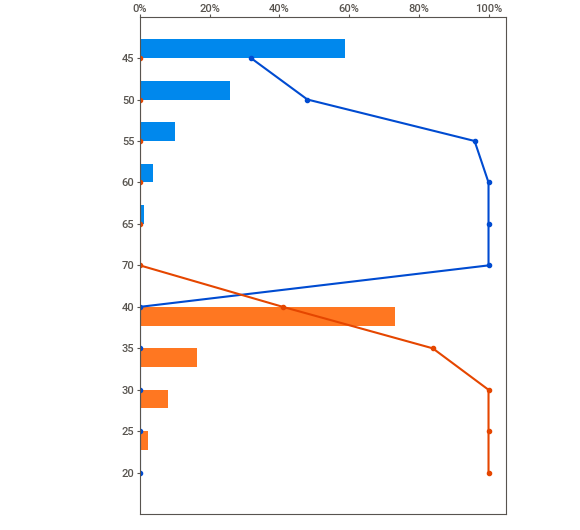
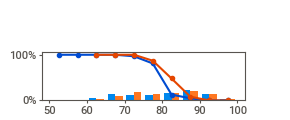
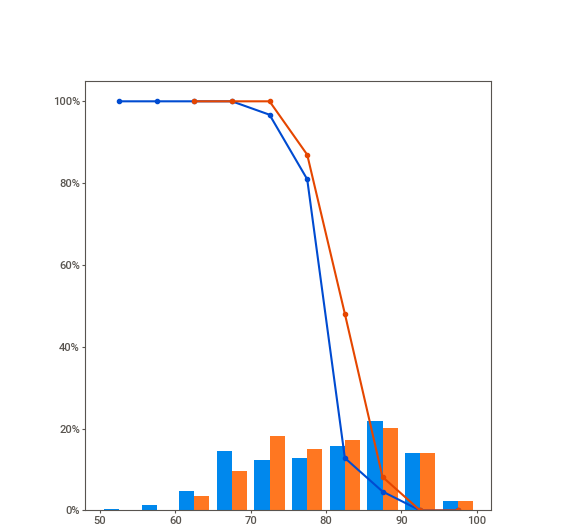
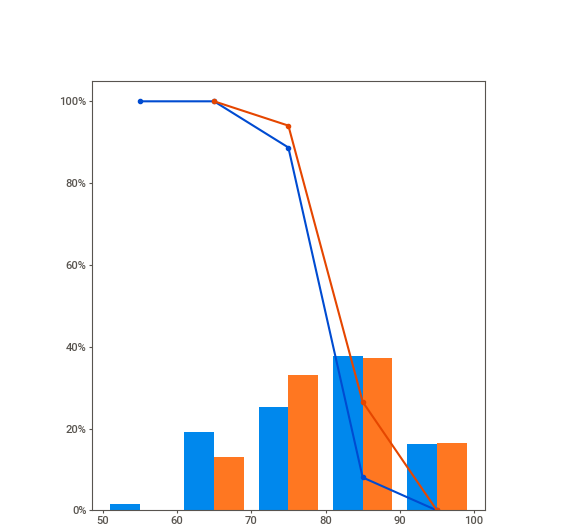
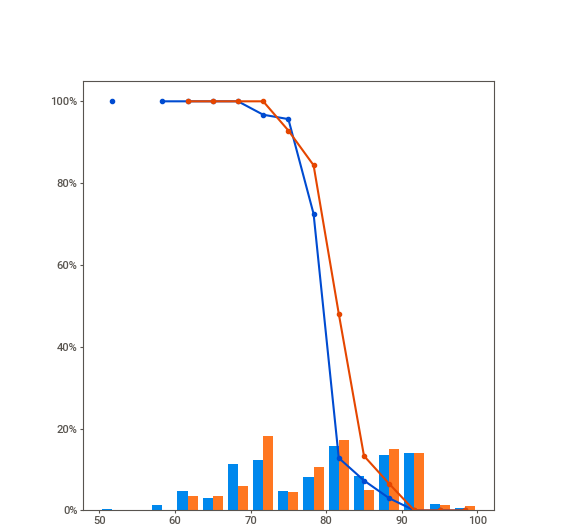
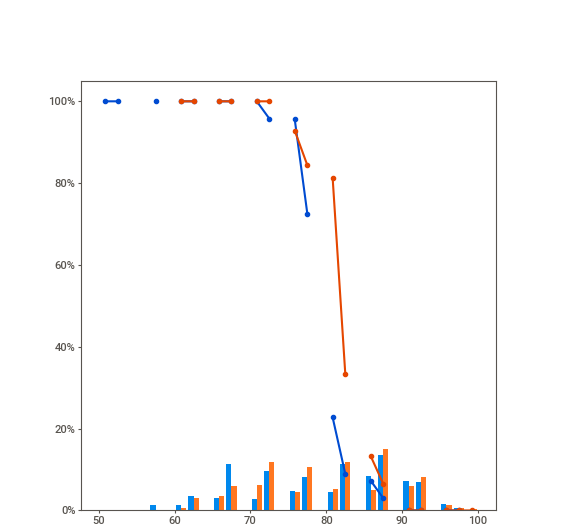
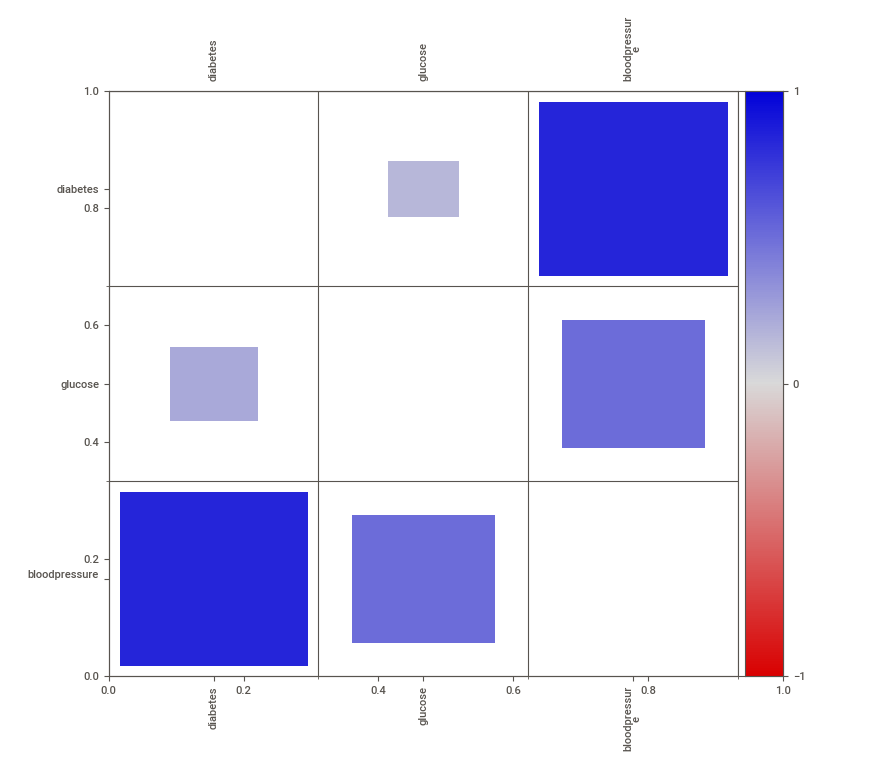
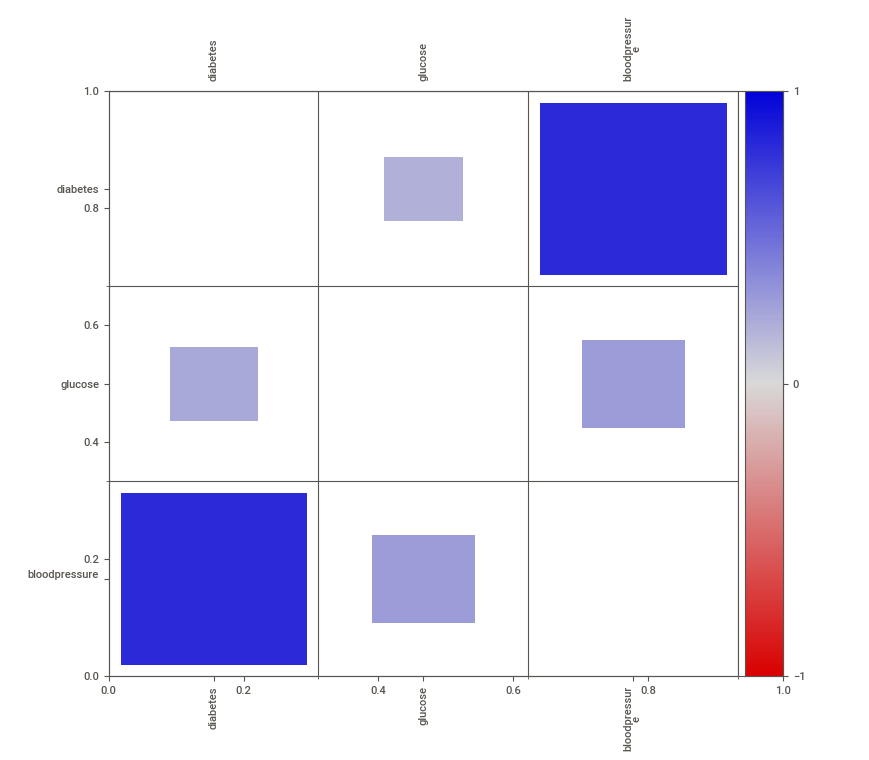

In [17]:
# Segmentamos los datos según el nivel de glucosa (> 40 vs <= 40) usando la variable objetivo real 'diabetes'
intra_report = sv.compare_intra(train_df,
                                train_df["glucose"] > 40,
                                 ["Glucosa > 40", "Glucosa <= 40"],
                                'diabetes')
intra_report.show_notebook(w=900, h=450, scale=0.8)